# HIT140 Objective 2: FIFA World Cup 2026, predicting goal difference and goals scored

**Group project, Assessment 3.** Two multiple linear regression tasks, each with exactly **8 explanatory variables**:

- **LR 2.1:** predict the **goal difference** of a match (104 rows, one per match).
- **LR 2.2:** predict the **goals scored by one team** in a match (208 rows, one per team per match).

Rules we follow: every variable must be **known before kick-off**, and the two models may **share at most 4** variables. We use exactly **4 shared + 4 unique variables for each model, so 12 different variables in total**.

**How to run:** put this notebook in `FINAL_SUBMISSION_CODE_DOCS/notebook/` and the CSV files in `FINAL_SUBMISSION_CODE_DOCS/data/`, then run all cells from the top (no Google Drive needed). Tables and figures are saved to `FINAL_SUBMISSION_CODE_DOCS/output/`.

```
FINAL_SUBMISSION_CODE_DOCS/
├── data/      fbref_matches.csv, the 2018 and 2022 World Cup stats files, team_appearances.csv,
│              worldcup2026_elo.csv, worldcup2026_market_value_transfermarkt_million.csv
├── notebook/  this notebook
└── output/    created by this notebook (figures and final datasets)
```

**Plan of the notebook**

1. Why we used several data sources (data source justification)
2. Load the six files and check them
3. Clean the data and join the sources together (one team-name spelling, Elo, squad value, World Cup history)
4. Understand the data (EDA)
5. Build the candidate variables using only information known before kick-off, and run a leak check
6. Step 1: availability audit. Step 2: choose the 4 shared + 4 unique variables with EDA (training matches only)
7. Train/test split, then Linear Regression 2.1 and 2.2 with five optimisation steps
8. Which variables matter? (ablation)
9. Other regression models, backtest, bootstrap and recommendations
10. Summary tables for the report

## 1. Data source justification

The brief points to three websites (FIFA, The Stats Don't Lie, FBref). They are good for **what happened inside the tournament**, but they say very little about **how strong each team was before it started**. Most groups will use only those three links, so their variables and findings will look alike. We wanted something new that would also teach us more about how football matches work, so we added **external sources** and joined them together. Handling six files with different team names, formats and time periods also taught us a lot about real-world data cleaning.

| Source (file) | What it gives us | Why the three recommended sites could not give it |
|---|---|---|
| `fbref_matches.csv` (FBref) | The 104 matches: date, kick-off time, venue, round, score | This is the **main table** and it is one of the recommended sites. |
| `worldcup2026_elo.csv` (World Football Elo ratings) | Elo rating of both teams **before** each match | A single number for team strength that is updated after every game. The recommended sites only show results and tables, not a pre-match strength rating. We only use the "before" column. |
| `worldcup2026_market_value_transfermarkt_million.csv` (Transfermarkt) | Squad market value in € million | The lecturer agreed Transfermarkt is a sensible source for pre-tournament information. Money spent on players is a different view of strength than results. |
| `team_appearances.csv` (historical World Cup database) | Every World Cup match since 1930: goals for/against, tournament | Gives **World Cup experience** and long-run goal difference for every team. FBref only shows the 2026 tournament. |
| 2018 and 2022 World Cup stats files (FootyStats format) | Match statistics: possession, shots, corners, cards, fouls, clean sheets | Gives each team's **playing style** from the last two World Cups, known before 2026 starts. Match statistics from 2026 itself cannot be used because they are only known after the match. |

*Source links: add the exact URLs we used here before submitting (FBref, eloratings/World Football Elo, Transfermarkt, the World Cup database, FootyStats).*

**What we did not use:** the FIFA ranking pages we found were published after the tournament, so they would leak the results. Bookmaker odds and 2026 match statistics are also not used, because the 2026 match-statistics file (`world_cup_match_data.csv`) was not part of the data we worked from; the model uses the six files above.

## 2. Setup and loading the six files

In [1]:
# Libraries
import re, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
import seaborn as sns
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan

from sklearn.preprocessing import PowerTransformer, StandardScaler
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV, ElasticNetCV, PoissonRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import GroupKFold, GridSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)

# Folders: this works when the notebook sits in .../notebook/ and the data in .../data/
DATA = Path("../data") if Path("../data").exists() else Path("data")
OUT = DATA.parent / "output"
(OUT / "figures").mkdir(parents=True, exist_ok=True)

# One colour scheme for every chart (colour-blind friendly)
BLUE, ORANGE, GREY, GREEN, RED = "#2E6FA7", "#E08A1E", "#8A8F98", "#3B9B6B", "#C0504D"
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

fb   = pd.read_csv(DATA / "fbref_matches.csv")
wc18 = pd.read_csv(DATA / "international-fifa-world-cup-2018-russia-matches-2018-to-2018-stats.csv")
wc22 = pd.read_csv(DATA / "international-fifa-world-cup-2022-qatar-matches-2022-to-2022-stats.csv")
apps = pd.read_csv(DATA / "team_appearances.csv")
elo  = pd.read_csv(DATA / "worldcup2026_elo.csv")
mv   = pd.read_csv(DATA / "worldcup2026_market_value_transfermarkt_million.csv")

role = {"fbref_matches.csv": "2026 matches (main table)", "worldcup2026_elo.csv": "pre-match Elo rating",
        "worldcup2026_market_value_transfermarkt_million.csv": "squad market value",
        "team_appearances.csv": "World Cup history since 1930", "wc18": "2018 match statistics", "wc22": "2022 match statistics"}
overview = pd.DataFrame([
    ("fbref_matches.csv", *fb.shape, role["fbref_matches.csv"]), ("worldcup2026_elo.csv", *elo.shape, role["worldcup2026_elo.csv"]),
    ("worldcup2026_market_value_transfermarkt_million.csv", *mv.shape, role["worldcup2026_market_value_transfermarkt_million.csv"]),
    ("team_appearances.csv", *apps.shape, role["team_appearances.csv"]),
    ("2018 Russia stats", *wc18.shape, role["wc18"]), ("2022 Qatar stats", *wc22.shape, role["wc22"]),
], columns=["file", "rows", "columns", "what it is used for"])
display(overview)

# A first look at the head of each file (only the columns we care about, to keep the output short)
display(fb[["Round", "Date", "Time", "Home", "Score", "Away", "Venue"]].head(3))
display(elo.head(3))
display(mv.head(3))
display(apps[["tournament_name", "match_date", "team_name", "opponent_name", "goals_for", "goals_against"]].head(3))
display(wc22[["date_GMT", "home_team_name", "away_team_name", "home_team_goal_count", "away_team_goal_count",
              "home_team_possession", "home_team_shots", "home_team_corner_count"]].head(3))

,file,rows,columns,what it is used for
0,fbref_matches.csv,104,13,2026 matches (main table)
1,worldcup2026_elo.csv,104,6,pre-match Elo rating
2,worldcup2026_market_value_transfermarkt_millio...,48,2,squad market value
3,team_appearances.csv,2496,36,World Cup history since 1930
4,2018 Russia stats,64,66,2018 match statistics
5,2022 Qatar stats,64,66,2022 match statistics


,Round,Date,Time,Home,Score,Away,Venue
0,Group stage,2026-06-11,13:00 (05:00),Mexico mx,2-0,za South Africa,Estadio Banorte (Neutral Site)
1,Group stage,2026-06-11,20:00 (12:00),Korea Republic kr,2-1,cz Czechia,Estadio Akron (Neutral Site)
2,Group stage,2026-06-12,15:00 (05:00),Canada ca,1-1,ba Bosnia-Herz,BMO Field (Neutral Site)


,Team1,Team2,Elo_team1_before,Elo_team2_before,Elo_team1_after,Elo_team2_after
0,Mexico,South Africa,1875,1517,1881,1511
1,South Korea,Czech Republic,1758,1740,1786,1712
2,Czech Republic,South Africa,1712,1511,1696,1527


,Nation,Market Value (€ million)
0,France,1450.0
1,England,1400.0
2,Spain,1350.0


,tournament_name,match_date,team_name,opponent_name,goals_for,goals_against
0,1930 FIFA Men's World Cup,1930-07-13,France,Mexico,4,1
1,1930 FIFA Men's World Cup,1930-07-13,Mexico,France,1,4
2,1930 FIFA Men's World Cup,1930-07-13,United States,Belgium,3,0


,date_GMT,home_team_name,away_team_name,home_team_goal_count,away_team_goal_count,home_team_possession,home_team_shots,home_team_corner_count
0,Nov 20 2022 - 4:00pm,Qatar,Ecuador,0,2,47,5,1
1,Nov 21 2022 - 1:00pm,England,Iran,6,2,78,13,8
2,Nov 21 2022 - 4:00pm,Senegal,Netherlands,0,2,47,16,6


**What we see.** Six files: the 104 matches (FBref), one Elo row per match (104), one squad value per team (48), the full World Cup history (2,496 team-match rows) and the 64 matches each of 2018 and 2022. The files use different team spellings, which is the main cleaning job.

## 3. Cleaning the data and joining the sources

Things that must be fixed before any modelling:

- **Penalty shoot-out scores** look like `(3) 1-1 (4)`. The number in brackets is the shoot-out, not goals. We keep the score *between* the brackets as the match score.
- **Team names** differ in every file (`USA`, `USMNT`, `United States`; `Türkiye`, `Turkiye`, `Turkey`; `Czechia`, `Czech Republic`...). We choose the spelling used in the Elo file as the one standard spelling and map everything to it. FBref also glues a country code to each name (`Mexico mx`, `za South Africa`), which we strip first.
- **Match order:** we sort by date and kick-off time and give each match an ID. The ID is a label only and is never used as a predictor.
- **Old teams:** in the history file, West Germany, Czechoslovakia and Zaire are counted as Germany, Czech Republic and DR Congo.

In [2]:
# ---- One standard spelling for every team (the Elo file's spelling) ----
ALIAS = {"Bosnia-Herz": "Bosnia and Herzegovina", "Bosnia-Herzegovina": "Bosnia and Herzegovina", "Cabo Verde": "Cape Verde",
         "Congo DR": "Dem. Rep. of Congo", "Democratic Republic of the Congo": "Dem. Rep. of Congo", "Czechia": "Czech Republic",
         "Côte d'Ivoire": "Ivory Coast", "IR Iran": "Iran", "Korea Republic": "South Korea", "Türkiye": "Turkey", "Turkiye": "Turkey",
         "USA": "United States", "USMNT": "United States"}
OLD_TEAMS = {"West Germany": "Germany", "Czechoslovakia": "Czech Republic", "Zaire": "Dem. Rep. of Congo"}
canon = lambda s: ALIAS.get(str(s).strip(), str(s).strip())

# ---- FBref 2026 matches ----
df = fb.copy()
df.columns = [c.strip().lower().replace(" ", "_") for c in df.columns]
df["went_to_penalties"] = df["score"].str.contains(r"\(\d+\)")                       # e.g. "(3) 1-1 (4)"
clean_score = df["score"].str.replace(r"\(\d+\)", "", regex=True)                   # keep only the match score
df[["home_goals", "away_goals"]] = clean_score.str.extract(r"(\d+)\s*-\s*(\d+)").astype(int)
df["extra_time"] = df["notes"].fillna("").str.contains("Extra Time|extra time")
df["home_team"] = df["home"].str.replace(r"\s+[a-z]{2,3}$", "", regex=True).str.strip().map(canon)   # code is at the END for home
df["away_team"] = df["away"].str.replace(r"^[a-z]{2,3}\s+", "", regex=True).str.strip().map(canon)   # code is at the START for away
df["venue_name"] = df["venue"].str.replace(r"\s*\(.*\)$", "", regex=True).str.strip()
t = df["time"].str.extract(r"^(\d{1,2}):(\d{2})").astype(int)                      # first time shown = local kick-off time
df["kickoff_hour"], df["kickoff_min"] = t[0], t[0] * 60 + t[1]
df["date"] = pd.to_datetime(df["date"])
df = df.sort_values(["date", "kickoff_min"], kind="stable").reset_index(drop=True)
df["match_id"] = np.arange(1, len(df) + 1)
df["goal_difference"] = df["home_goals"] - df["away_goals"]                         # target of LR 2.1 (home minus away)
df["stage"] = np.where(df["round"].eq("Group stage"), "Group", "Knockout")
df[["match_id", "date", "round", "home_team", "home_goals", "away_goals", "away_team", "went_to_penalties"]].head()

,match_id,date,round,home_team,home_goals,away_goals,away_team,went_to_penalties
0,1,2026-06-11,Group stage,Mexico,2,0,South Africa,False
1,2,2026-06-11,Group stage,South Korea,2,1,Czech Republic,False
2,3,2026-06-12,Group stage,Canada,1,1,Bosnia and Herzegovina,False
3,4,2026-06-12,Group stage,United States,4,1,Paraguay,False
4,5,2026-06-13,Group stage,Qatar,1,1,Switzerland,False


In [3]:
# ---- Integrity checks on the main table. If one fails the notebook stops, so bad data cannot reach the models. ----
teams = pd.concat([df.home_team, df.away_team])
checks = {
    "104 matches": len(df) == 104,
    "no missing goals": df[["home_goals", "away_goals"]].notna().all().all(),
    "no duplicate fixtures": not df.duplicated(["date", "home_team", "away_team"]).any(),
    "48 distinct teams": teams.nunique() == 48,
    "72 group + 32 knockout": df.stage.value_counts().to_dict() == {"Group": 72, "Knockout": 32},
    "each team played 3 group games": (pd.concat([df[df.stage == "Group"].home_team, df[df.stage == "Group"].away_team]).value_counts() == 3).all(),
    "4 penalty shoot-outs found": df.went_to_penalties.sum() == 4,
    "dates in order": df.date.is_monotonic_increasing,
}
for k, v in checks.items():
    print(("PASS " if v else "FAIL ") + k)
assert all(checks.values())

# ---- Do the other files cover the same 48 teams? ----
TEAMS48 = set(teams)
elo["Team1"], elo["Team2"] = elo["Team1"].map(canon), elo["Team2"].map(canon)
mv["team"] = mv["Nation"].map(canon)
print("\nElo covers the 48 teams:           ", set(elo.Team1) | set(elo.Team2) == TEAMS48)
print("Market value covers the 48 teams:  ", set(mv.team) == TEAMS48)
print("Missing values in market value:    ", int(mv["Market Value (€ million)"].isna().sum()))
assert set(elo.Team1) | set(elo.Team2) == TEAMS48 and set(mv.team) == TEAMS48

PASS 104 matches
PASS no missing goals
PASS no duplicate fixtures
PASS 48 distinct teams
PASS 72 group + 32 knockout
PASS each team played 3 group games
PASS 4 penalty shoot-outs found
PASS dates in order

Elo covers the 48 teams:            True
Market value covers the 48 teams:   True
Missing values in market value:     0


In [4]:
# ---- Join the Elo ratings to the matches ----
# The Elo file has no dates, so we match on the pair of teams (home/away order can differ). If a pair meets twice, the n-th meeting is matched in order.
pair = lambda a, b: ["|".join(sorted(p)) for p in zip(a, b)]
df["pair"] = pair(df.home_team, df.away_team);  df["pair_n"] = df.groupby("pair").cumcount()
elo["pair"] = pair(elo.Team1, elo.Team2);       elo["pair_n"] = elo.groupby("pair").cumcount()
print("Pairs that meet twice in the tournament:", int((df.groupby('pair').size() > 1).sum()))
df = df.merge(elo, on=["pair", "pair_n"], how="left", validate="one_to_one")
assert df.Elo_team1_before.notna().all(), "every match must find its Elo row"

# Put Elo into home/away order. We keep the "after" ratings ONLY for an integrity check; they are never a predictor (they contain the result).
t1_home = df.Team1.eq(df.home_team)
df["home_elo"]       = np.where(t1_home, df.Elo_team1_before, df.Elo_team2_before)
df["away_elo"]       = np.where(t1_home, df.Elo_team2_before, df.Elo_team1_before)
df["home_elo_after"] = np.where(t1_home, df.Elo_team1_after,  df.Elo_team2_after)
df["away_elo_after"] = np.where(t1_home, df.Elo_team2_after,  df.Elo_team1_after)

# Integrity check: a team's Elo AFTER one match must equal its Elo BEFORE the next match. If the join were wrong, this would fail.
long_chk = pd.concat([df[["match_id", "home_team", "home_elo", "home_elo_after"]].set_axis(["match_id", "team", "before", "after"], axis=1),
                      df[["match_id", "away_team", "away_elo", "away_elo_after"]].set_axis(["match_id", "team", "before", "after"], axis=1)]).sort_values(["team", "match_id"])
prev_after = long_chk.groupby("team")["after"].shift(1)
ok = (prev_after.dropna() == long_chk.loc[prev_after.notna(), "before"]).mean()
print(f"Elo chain check: {ok:.1%} of consecutive matches line up (after one game = before the next)")
assert ok == 1.0

Pairs that meet twice in the tournament: 0
Elo chain check: 100.0% of consecutive matches line up (after one game = before the next)


**Result of the checks.** All eight integrity checks pass: 104 matches, 48 teams, 72 group + 32 knockout, all four shoot-out scores read correctly. The Elo join found a row for every match, and the **Elo chain check is 100%**: a team's rating after one match equals its rating before the next. That proves the Elo rows were matched to the right matches and that "Elo before" only holds information from earlier games.

In [5]:
# ---- Squad market value, World Cup history (team_appearances) and 2018/2022 playing style, one row per team ----
team = pd.DataFrame(index=sorted(TEAMS48)); team.index.name = "team"

# (a) Squad market value in € million, on a log scale because it is very skewed (France 1450 vs Iraq 17)
team["mv_log"] = np.log(mv.set_index("team")["Market Value (€ million)"])

# (b) World Cup history: men's tournaments before 2026 only
a = apps[apps.tournament_name.str.contains("Men's")].copy()
a["team"] = a.team_name.replace(OLD_TEAMS).map(canon)
a = a[a.team.isin(TEAMS48)]
team["wc_exp"] = a.groupby("team").tournament_id.nunique().reindex(team.index).fillna(0)       # number of earlier World Cups played
n_hist = a.groupby("team").size().reindex(team.index).fillna(0)
gd_sum = a.groupby("team").goal_differential.sum().reindex(team.index).fillna(0)
K_GD = 5                                                                                         # 5 pseudo-matches of "average" (0 goal difference)
team["hist_gd"] = gd_sum / (n_hist + K_GD)                                                       # shrunk goal difference per World Cup match

# (c) Playing style from the 2018 and 2022 World Cups (FootyStats files). One row per team per match first.
def long_stats(w):
    rows = []
    for me, op in [("home", "away"), ("away", "home")]:
        rows.append(pd.DataFrame({
            "team": w[f"{me}_team_name"].map(canon),
            "poss": w[f"{me}_team_possession"], "shots": w[f"{me}_team_shots"], "corners": w[f"{me}_team_corner_count"],
            "fouls": w[f"{me}_team_fouls"], "cards": w[f"{me}_team_yellow_cards"] + 2 * w[f"{me}_team_red_cards"],   # yellow = 1 point, red = 2
            "sot_conceded": w[f"{op}_team_shots_on_target"], "clean_sheet": (w[f"{op}_team_goal_count"] == 0).astype(int)}))
    return pd.concat(rows)
hs = pd.concat([long_stats(wc18), long_stats(wc22)])
n_style = hs.groupby("team").size()
K_STYLE = 2                                                                                      # pull towards the all-team average, 2 pseudo-matches
for c, name in [("poss", "hist_poss"), ("shots", "hist_shots"), ("corners", "hist_corners"), ("fouls", "hist_fouls"),
                ("cards", "hist_cards"), ("sot_conceded", "hist_sot_conc"), ("clean_sheet", "hist_cs")]:
    s = hs.groupby("team")[c].sum().reindex(team.index).fillna(0); n = n_style.reindex(team.index).fillna(0)
    team[name] = (s + K_STYLE * hs[c].mean()) / (n + K_STYLE)          # a team with no 2018/2022 games simply gets the average (no information)
team["n_style_matches"] = n_style.reindex(team.index).fillna(0)

# (d) Fixed facts: confederation (UEFA and CONMEBOL are the historically strongest) and host countries
CONFED = {"CONCACAF": ["Mexico", "United States", "Canada", "Haiti", "Curaçao", "Panama"],
          "CAF": ["South Africa", "Egypt", "Morocco", "Tunisia", "Senegal", "Ghana", "Ivory Coast", "Algeria", "Cape Verde", "Dem. Rep. of Congo"],
          "AFC": ["South Korea", "Qatar", "Australia", "Japan", "Saudi Arabia", "Iran", "Iraq", "Jordan", "Uzbekistan"],
          "OFC": ["New Zealand"], "CONMEBOL": ["Brazil", "Ecuador", "Uruguay", "Argentina", "Paraguay", "Colombia"],
          "UEFA": ["Czech Republic", "Bosnia and Herzegovina", "Switzerland", "Turkey", "Scotland", "Germany", "Netherlands", "Sweden", "Belgium",
                   "Spain", "France", "Norway", "Austria", "Portugal", "England", "Croatia"]}
team_confed = {t: c for c, ts in CONFED.items() for t in ts}
assert set(team_confed) == TEAMS48, "the confederation map must cover all 48 teams"
team["strong_confed"] = team.index.map(team_confed).isin(["UEFA", "CONMEBOL"]).astype(int)

VENUE_COUNTRY = {"Estadio Banorte": "Mexico", "Estadio Akron": "Mexico", "Estadio BBVA": "Mexico", "BMO Field": "Canada", "BC Place Stadium": "Canada"}
HOST_OF = {"Mexico": "Mexico", "Canada": "Canada", "United States": "USA"}
df["venue_country"] = df.venue_name.map(VENUE_COUNTRY).fillna("USA")

print("Teams with no 2018/2022 World Cup match (they get the all-team average style):", int((team.n_style_matches == 0).sum()), "of 48")
print("Teams that never played a World Cup before 2026:", int((team.wc_exp == 0).sum()), "of 48")
display(team.round(2).sort_values("mv_log", ascending=False).head(5))

Teams with no 2018/2022 World Cup match (they get the all-team average style): 18 of 48
Teams that never played a World Cup before 2026: 4 of 48


,mv_log,wc_exp,hist_gd,hist_poss,hist_shots,hist_corners,hist_fouls,hist_cards,hist_sot_conc,hist_cs,n_style_matches,strong_confed
team,,,,,,,,,,,,
France,7.28,16.0,0.65,49.88,11.58,4.26,11.60,1.47,3.43,0.35,14.0,1
England,7.24,16.0,0.46,56.79,11.02,5.22,10.62,0.90,3.14,0.33,12.0,1
Spain,7.21,16.0,0.46,69.70,11.93,5.41,10.07,0.76,2.49,0.36,8.0,1
Germany,7.17,20.0,0.87,61.62,16.92,7.39,10.08,1.45,4.36,0.07,6.0,1
Portugal,6.91,8.0,0.50,56.09,10.39,5.56,12.33,1.51,3.63,0.23,9.0,1


**What we built.** One row per team with squad value, World Cup experience, shrunk historical goal difference and 2018/2022 playing style. 18 of 48 teams did not play in 2018 or 2022; they get the all-team average (no information) instead of a made-up value. Only 4 teams had never played a World Cup before.

## 4. Understanding the data (EDA)

Before choosing variables we look at the data itself: how many goals are scored, whether stage matters, and how the strength measures relate to each other. These charts guide the variable choice later.

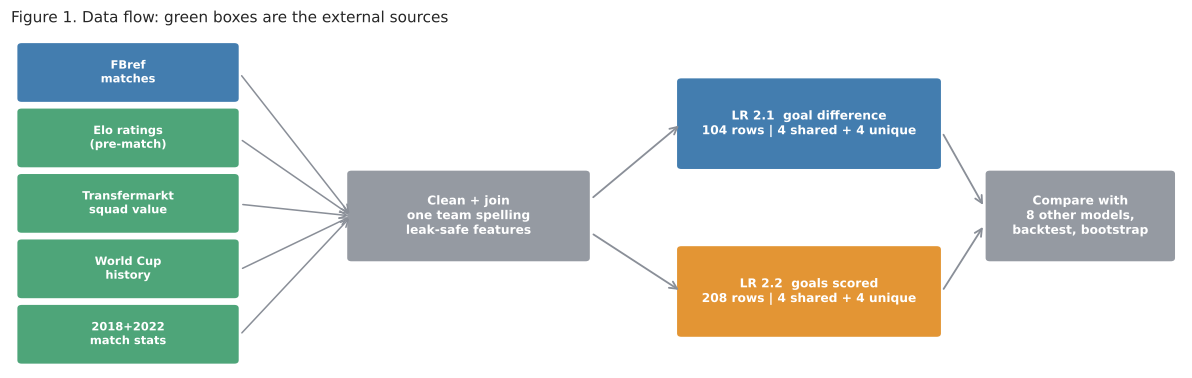

In [6]:
# Figure 1: how the six sources feed the two models (a simple diagram)
fig, ax = plt.subplots(figsize=(11, 3.6)); ax.axis("off"); ax.set_xlim(0, 11); ax.set_ylim(0, 4)
def box(x, y, w, h, text, color, fs=8):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.04", fc=color, ec="none", alpha=.9))
    ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=fs, color="white", weight="bold")
srcs = [("FBref\nmatches", BLUE), ("Elo ratings\n(pre-match)", GREEN), ("Transfermarkt\nsquad value", GREEN), ("World Cup\nhistory", GREEN), ("2018+2022\nmatch stats", GREEN)]
for i, (t_, c_) in enumerate(srcs):
    box(0.1, 3.2 - i * 0.78, 2.0, 0.62, t_, c_, 7.5)
    ax.annotate("", xy=(3.2, 1.8), xytext=(2.15, 3.5 - i * 0.78), arrowprops=dict(arrowstyle="->", color=GREY, lw=1))
box(3.2, 1.3, 2.2, 1.0, "Clean + join\none team spelling\nleak-safe features", GREY, 8)
ax.annotate("", xy=(6.3, 2.9), xytext=(5.45, 2.0), arrowprops=dict(arrowstyle="->", color=GREY, lw=1.2))
ax.annotate("", xy=(6.3, 0.9), xytext=(5.45, 1.6), arrowprops=dict(arrowstyle="->", color=GREY, lw=1.2))
box(6.3, 2.4, 2.4, 1.0, "LR 2.1  goal difference\n104 rows | 4 shared + 4 unique", BLUE, 8)
box(6.3, 0.4, 2.4, 1.0, "LR 2.2  goals scored\n208 rows | 4 shared + 4 unique", ORANGE, 8)
box(9.2, 1.3, 1.7, 1.0, "Compare with\n8 other models,\nbacktest, bootstrap", GREY, 8)
ax.annotate("", xy=(9.15, 1.9), xytext=(8.75, 2.8), arrowprops=dict(arrowstyle="->", color=GREY, lw=1.2))
ax.annotate("", xy=(9.15, 1.7), xytext=(8.75, 0.9), arrowprops=dict(arrowstyle="->", color=GREY, lw=1.2))
ax.set_title("Figure 1. Data flow: green boxes are the external sources", fontsize=10, loc="left")
plt.tight_layout(); plt.savefig(OUT / "figures/fig1_data_flow.png", dpi=200); plt.show()

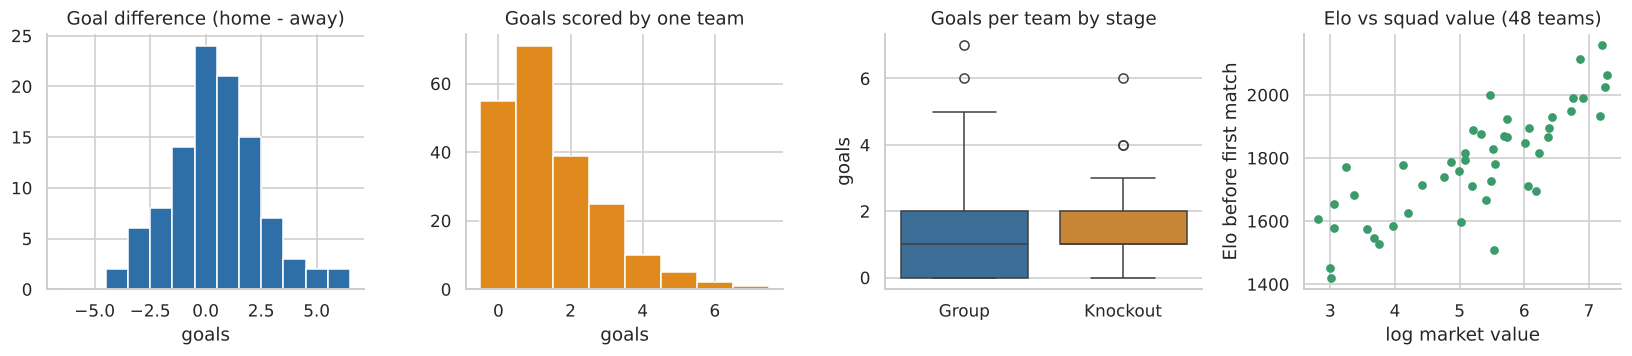

Mean goals per team per match: 1.48 | variance: 1.94
Draws: 24 of 104 matches | biggest win margin: 6
Mean goals per team: group = 1.49 | knockout = 1.45
Correlation between Elo and log squad value (48 teams): r = 0.81


In [7]:
# Figure 2: the two targets, stage differences, and how strong the strength measures are linked
long_goals = pd.concat([df[["stage", "home_goals"]].rename(columns={"home_goals": "goals"}), df[["stage", "away_goals"]].rename(columns={"away_goals": "goals"})])
fig, axes = plt.subplots(1, 4, figsize=(15, 3.4))
axes[0].hist(df.goal_difference, bins=np.arange(-6.5, 7.5, 1), color=BLUE, edgecolor="white"); axes[0].set(title="Goal difference (home - away)", xlabel="goals")
axes[1].hist(long_goals.goals, bins=np.arange(-0.5, 8.5, 1), color=ORANGE, edgecolor="white"); axes[1].set(title="Goals scored by one team", xlabel="goals")
sns.boxplot(data=long_goals, x="stage", y="goals", ax=axes[2], palette=[BLUE, ORANGE]); axes[2].set(title="Goals per team by stage", xlabel="")
e = pd.concat([df[["home_team", "home_elo"]].set_axis(["team", "elo"], axis=1), df[["away_team", "away_elo"]].set_axis(["team", "elo"], axis=1)]).groupby("team").elo.first()
axes[3].scatter(team.loc[e.index, "mv_log"], e, color=GREEN, s=22); axes[3].set(title="Elo vs squad value (48 teams)", xlabel="log market value", ylabel="Elo before first match")
plt.tight_layout(); plt.savefig(OUT / "figures/fig2_eda_overview.png", dpi=200); plt.show()

print("Mean goals per team per match:", round(long_goals.goals.mean(), 2), "| variance:", round(long_goals.goals.var(), 2))
print("Draws:", int((df.goal_difference == 0).sum()), "of 104 matches | biggest win margin:", int(df.goal_difference.abs().max()))
print("Mean goals per team: group =", round(long_goals[long_goals.stage == 'Group'].goals.mean(), 2), "| knockout =", round(long_goals[long_goals.stage == 'Knockout'].goals.mean(), 2))
print("Correlation between Elo and log squad value (48 teams): r =", round(np.corrcoef(team.loc[e.index, 'mv_log'], e)[0, 1], 2))

**What the EDA shows.** Teams score 1.48 goals per match on average (variance 1.94, so goals are slightly more spread out than a pure count process). 24 of 104 matches were draws and the biggest margin was 6. Group and knockout matches have almost the same goals per team (1.49 vs 1.45), so stage will not be a strong predictor. Elo and squad value are strongly linked (r = 0.81): they both measure team strength, which we must keep in mind for multicollinearity.

## 5. Building the candidate variables (only information known before kick-off)

We build one table with **one row per team per match** and add everything we know about each team *before that match*.

- **Fixed before the tournament:** Elo rating before the match, squad value, World Cup history, 2018/2022 playing style, confederation.
- **Changes during the tournament but only from earlier games:** goals scored and conceded and clean sheets in earlier 2026 matches ("form"), rest days since the previous match.
- **Match facts known in advance:** knockout or group stage, local kick-off hour, whether a host nation plays in its own country.

**The first-match problem.** In a team's first game it has no 2026 history. Filling this with zero would claim "this team never scores", which is false. We use a **shrunk average**: `(goals so far + K × tournament average) / (matches so far + K)` with K = 2. A team with no games starts at the tournament average (or 1.3 goals before the very first match) and moves towards its own record as games are played. The tournament average itself uses only earlier days.

In [8]:
# ---- Long table: one row per team per match ----
def side(d, me, opp, gf, ga, elo_me, listed_home):
    out = d[["match_id", "date", "stage", "venue_country", "kickoff_hour"]].copy()
    out["team"], out["opp"] = d[me], d[opp]
    out["gf"], out["ga"] = d[gf], d[ga]
    out["elo"] = d[elo_me]                       # Elo BEFORE the match
    out["listed_home"] = listed_home             # 1 if FBref lists the team first (a label only: all World Cup venues are neutral)
    return out
tg = pd.concat([side(df, "home_team", "away_team", "home_goals", "away_goals", "home_elo", 1),
                side(df, "away_team", "home_team", "away_goals", "home_goals", "away_elo", 0)])
tg = tg.sort_values(["date", "match_id", "listed_home"], ascending=[True, True, False]).reset_index(drop=True)

# These columns describe the match result. They are used ONLY to build form from EARLIER matches (see add_form).
tg["cs"] = (tg.ga == 0).astype(int)

# Team-level facts that do not depend on 2026 results
for c in ["mv_log", "wc_exp", "hist_gd", "hist_poss", "hist_shots", "hist_corners", "hist_fouls", "hist_cards", "hist_sot_conc", "hist_cs", "strong_confed"]:
    tg[c] = tg.team.map(team[c])
tg["host"] = (tg.team.map(HOST_OF) == tg.venue_country).astype(int)             # a host nation playing in its own country
tg["knockout"] = (tg.stage == "Knockout").astype(int)
tg["rest_days"] = (tg.date - tg.groupby("team").date.shift(1)).dt.days.fillna(7).clip(upper=7)   # first match = fully rested (7)

FALLBACK = {"gf": 1.3, "ga": 1.3, "cs": 0.25}   # only used for the opening day, when no earlier match exists

def add_form(tg, K=2):
    # Shrunk average of an outcome over the team's EARLIER matches only.
    t = tg.copy()
    for s in ["gf", "ga", "cs"]:
        prior = {d: (t[t.date < d][s].mean() if (t.date < d).any() else FALLBACK[s]) for d in sorted(t.date.unique())}   # average of strictly earlier days
        prev_sum = t.groupby("team")[s].cumsum() - t[s]            # this team's earlier matches only (current one removed)
        n_prev = t.groupby("team").cumcount()
        t[f"{s}_form"] = (prev_sum + K * t.date.map(prior)) / (n_prev + K)
    return t
tgf = add_form(tg, K=2)
tgf[["match_id", "team", "opp", "gf", "elo", "mv_log", "wc_exp", "gf_form", "ga_form", "rest_days", "host"]].head(6).round(2)

,match_id,team,opp,gf,elo,mv_log,wc_exp,gf_form,ga_form,rest_days,host
0,1,Mexico,South Africa,2,1875,5.33,17.0,1.30,1.30,7.0,1
1,1,South Africa,Mexico,0,1517,3.75,3.0,1.30,1.30,7.0,0
2,2,South Korea,Czech Republic,2,1758,4.99,11.0,1.30,1.30,7.0,0
3,2,Czech Republic,South Korea,1,1740,5.19,9.0,1.30,1.30,7.0,0
4,3,Canada,Bosnia and Herzegovina,1,1788,4.87,2.0,1.25,1.25,7.0,1
5,3,Bosnia and Herzegovina,Canada,1,1595,5.03,1.0,1.25,1.25,7.0,0


In [9]:
# ---- Datasets for the two tasks, with ALL candidate variables ----
TEAM_COLS = ["elo", "mv_log", "wc_exp", "hist_gd", "host", "rest_days", "hist_poss", "hist_cards", "hist_corners", "hist_fouls", "strong_confed",
             "gf_form", "ga_form", "cs_form", "hist_shots", "hist_sot_conc", "hist_cs", "kickoff_hour", "knockout"]

def assemble(tg_f):
    lk = tg_f.set_index(["match_id", "team"])[TEAM_COLS]
    # ---- LR 2.1: one row per match; team-strength variables are HOME minus AWAY ----
    H = lk.loc[list(zip(df.match_id, df.home_team))].reset_index(drop=True)
    A = lk.loc[list(zip(df.match_id, df.away_team))].reset_index(drop=True)
    m21 = df[["match_id", "date", "round", "home_team", "away_team", "home_goals", "away_goals", "goal_difference"]].copy()
    m21["elo_diff"], m21["mv_diff"], m21["wcexp_diff"] = H.elo - A.elo, H.mv_log - A.mv_log, H.wc_exp - A.wc_exp
    m21["histgd_diff"], m21["host_diff"] = H.hist_gd - A.hist_gd, H.host - A.host
    m21["rest_days_diff"], m21["hist_poss_diff"], m21["hist_cards_diff"] = H.rest_days - A.rest_days, H.hist_poss - A.hist_poss, H.hist_cards - A.hist_cards
    m21["hist_corners_diff"], m21["hist_fouls_diff"] = H.hist_corners - A.hist_corners, H.hist_fouls - A.hist_fouls
    m21["strong_confed_diff"] = H.strong_confed - A.strong_confed
    # ---- LR 2.2: one row per team per match; shared variables are TEAM minus OPPONENT, unique ones describe the team's attack and the opponent's defence ----
    T_ = lk.loc[list(zip(tg_f.match_id, tg_f.team))].reset_index(drop=True)
    O_ = lk.loc[list(zip(tg_f.match_id, tg_f.opp))].reset_index(drop=True)
    m22 = tg_f[["match_id", "date", "team", "opp", "gf"]].rename(columns={"gf": "goals_scored"}).reset_index(drop=True)
    m22["elo_diff"], m22["mv_diff"], m22["wcexp_diff"] = T_.elo - O_.elo, T_.mv_log - O_.mv_log, T_.wc_exp - O_.wc_exp
    m22["histgd_diff"], m22["host_diff"] = T_.hist_gd - O_.hist_gd, T_.host - O_.host
    m22["team_form_gf"], m22["opp_form_ga"], m22["opp_form_cs"] = T_.gf_form, O_.ga_form, O_.cs_form
    m22["team_hist_shots"], m22["opp_hist_sot_conc"], m22["opp_hist_cs"] = T_.hist_shots, O_.hist_sot_conc, O_.hist_cs
    m22["kickoff_hour"], m22["knockout"] = T_.kickoff_hour, T_.knockout
    return m21, m22

SHARED_POOL = ["elo_diff", "mv_diff", "wcexp_diff", "histgd_diff", "host_diff"]
POOL21 = ["rest_days_diff", "hist_poss_diff", "hist_cards_diff", "hist_corners_diff", "hist_fouls_diff", "strong_confed_diff"]
POOL22 = ["team_form_gf", "opp_form_ga", "opp_form_cs", "team_hist_shots", "opp_hist_sot_conc", "opp_hist_cs", "kickoff_hour", "knockout"]

m21, m22 = assemble(tgf)
T21, T22 = "goal_difference", "goals_scored"
assert len(m21) == 104 and len(m22) == 208
assert m21[SHARED_POOL + POOL21].notna().all().all() and m22[SHARED_POOL + POOL22].notna().all().all(), "no missing values allowed"
print("LR 2.1 candidates:", m21.shape, "| LR 2.2 candidates:", m22.shape)
print("Candidates for 2.1:", len(SHARED_POOL + POOL21), "| candidates for 2.2:", len(SHARED_POOL + POOL22))

LR 2.1 candidates: (104, 19) | LR 2.2 candidates: (208, 18)
Candidates for 2.1: 11 | candidates for 2.2: 13


In [10]:
# ---- LEAK CHECK: rebuild the form of one team the slow, obvious way for random matches and compare with the stored value. ----
# If any match could "see" its own result or a later one, the numbers would differ.
rng = np.random.default_rng(SEED)
for mid in rng.choice(df.match_id.values, 8, replace=False):
    row = df[df.match_id == mid].iloc[0]
    past = tg[tg.date < row.date]                                              # strictly earlier days
    tp = tg[(tg.team == row.home_team) & (tg.date < row.date)]                # this team's earlier matches
    for s in ["gf", "ga", "cs"]:
        prior = past[s].mean() if len(past) else FALLBACK[s]
        slow = (tp[s].sum() + 2 * prior) / (len(tp) + 2)
        stored = tgf[(tgf.match_id == mid) & (tgf.team == row.home_team)][f"{s}_form"].iloc[0]
        assert abs(slow - stored) < 1e-9, (mid, s, slow, stored)
print("Leak check 1 passed: stored form = form recomputed from earlier days only.")

# Extra proof: shuffle the RESULTS of the last 20 matches. Features of the first 84 matches must not change at all.
alt = tg.copy(); shuf = alt.match_id > 84
alt.loc[shuf, ["gf", "ga", "cs"]] = alt.loc[shuf, ["gf", "ga", "cs"]].sample(frac=1, random_state=1).values
a1, a2 = assemble(add_form(alt, 2))
assert np.allclose(m22[m22.match_id <= 84][POOL22 + SHARED_POOL].values, a2[a2.match_id <= 84][POOL22 + SHARED_POOL].values), "features changed!"
print("Leak check 2 passed: changing the results of matches 85+ does not change any feature of matches 1-84.")
op = m21.iloc[0]
print(f"Opening match ({op.home_team} v {op.away_team}): no 2026 history, so form is the neutral 1.3 goals for both; Elo difference = {op.elo_diff:.0f}.")

Leak check 1 passed: stored form = form recomputed from earlier days only.


Leak check 2 passed: changing the results of matches 85+ does not change any feature of matches 1-84.
Opening match (Mexico v South Africa): no 2026 history, so form is the neutral 1.3 goals for both; Elo difference = 358.


**Result.** The candidate tables have the right shape (104 and 208 rows, no missing values). Both leak checks pass: form recomputed by hand from earlier days equals the stored value, and **shuffling the results of matches 85 to 104 does not change any feature of matches 1 to 84**. In the opening match both teams get the neutral 1.3 goals form, as intended.

## 6. Choosing the variables: availability audit, then EDA

**Step 1: availability.** A variable may only be used if it is known *before* kick-off. Otherwise the model would "predict" a match with information from the match itself. Every column of every source is listed below with a verdict.

In [11]:
audit = pd.DataFrame([
 ("fbref: Score, goals, extra time, penalties",         "No",  "This is the result itself. Used only as the target and to build form from EARLIER matches."),
 ("fbref: Attendance, Referee, Match Report, Notes",     "No",  "Attendance and notes are only known after the match (the referee is known earlier but has no numeric signal)."),
 ("fbref: Date, Time, Venue, Round",                     "Yes", "The schedule is published before the tournament. Used for knockout, kick-off hour, host-in-own-country and rest days."),
 ("Elo: Elo_before (both teams)",                        "Yes", "The rating just before kick-off. Used."),
 ("Elo: Elo_after (both teams)",                         "No",  "It already contains the match result. Used ONLY in the chain check (after one game = before the next)."),
 ("Transfermarkt: Market Value",                         "Yes", "A pre-tournament squad value. Used (log scale)."),
 ("team_appearances: World Cups before 2026",            "Yes", "Past tournaments only (2026 is not in the file). Used for experience and historical goal difference."),
 ("2018/2022 stats: possession, shots, corners, cards, fouls, clean sheets", "Yes", "Past tournaments, so known before 2026. Used as playing-style variables."),
 ("2018/2022 stats: bookmaker odds, pre-match xG, PPG", "Not used", "Past-tournament odds do not describe 2026 opponents, so we leave them out."),
 ("Any 2026 in-match statistic (shots, possession, cards...)", "No", "Only known after the match. Not used."),
], columns=["column / source", "known before kick-off?", "decision"])
display(audit)

,column / source,known before kick-off?,decision
0,"fbref: Score, goals, extra time, penalties",No,This is the result itself. Used only as the ta...
1,"fbref: Attendance, Referee, Match Report, Notes",No,Attendance and notes are only known after the ...
2,"fbref: Date, Time, Venue, Round",Yes,The schedule is published before the tournamen...
3,Elo: Elo_before (both teams),Yes,The rating just before kick-off. Used.
4,Elo: Elo_after (both teams),No,It already contains the match result. Used ONL...
5,Transfermarkt: Market Value,Yes,A pre-tournament squad value. Used (log scale).
6,team_appearances: World Cups before 2026,Yes,Past tournaments only (2026 is not in the file...
7,"2018/2022 stats: possession, shots, corners, c...",Yes,"Past tournaments, so known before 2026. Used a..."
8,"2018/2022 stats: bookmaker odds, pre-match xG,...",Not used,Past-tournament odds do not describe 2026 oppo...
9,"Any 2026 in-match statistic (shots, possession...",No,Only known after the match. Not used.


**Result.** Only information that exists before kick-off is used. The one trap in the data is `Elo_after`, which already contains the result: we use it only to prove the Elo join is correct.

**Step 2: EDA to choose the variables.** For each candidate we write down the **expected sign first** (so the choice is not just "what fits best"), then look at the Pearson correlation with the target using **training matches only**, and check **multicollinearity (VIF)**.

| Variable | Meaning | Expected sign in 2.1 | Expected sign in 2.2 |
|---|---|---|---|
| `elo_diff` | Elo before the match, team minus opponent | + | + |
| `mv_diff` | log squad value, team minus opponent | + | + |
| `wcexp_diff` | number of earlier World Cups, team minus opponent | + | + |
| `histgd_diff` | historical World Cup goal difference per match (shrunk), team minus opponent | + | + |
| `host_diff` | host nation playing in its own country | + | + |
| `rest_days_diff` | days of rest, home minus away | + | – |
| `hist_poss_diff` | 2018/22 average possession | + | – |
| `hist_cards_diff` | 2018/22 cards per match (yellow = 1, red = 2) | – | – |
| `hist_corners_diff` | 2018/22 corners per match | + | – |
| `hist_fouls_diff` | 2018/22 fouls per match | – | – |
| `strong_confed_diff` | team from UEFA/CONMEBOL | + | – |
| `team_form_gf` | goals scored per game so far in 2026 (shrunk) | – | + |
| `opp_form_ga` | goals the opponent concedes per game so far | – | + |
| `opp_form_cs` | opponent's clean-sheet rate so far | – | – |
| `team_hist_shots` | team's shots per match in 2018/22 | – | + |
| `opp_hist_sot_conc` | shots on target the opponent conceded in 2018/22 | – | + |
| `opp_hist_cs` | opponent's clean-sheet rate in 2018/22 | – | – |
| `kickoff_hour` | local kick-off hour (afternoon heat?) | – | none |
| `knockout` | 1 for knockout matches (tighter, more cautious play?) | – | – |

A dash (–) means "not used in that model". The five shared candidates are tested in **both** models. The unique candidates live in only one model's pool, so the two unique sets can never overlap.

In [12]:
# ---- Split FIRST (chronological): first 83 matches train, last 21 test. Selection uses the training matches only. ----
N_TRAIN = int(0.8 * 104)                              # 83 matches
tr21, te21 = m21[m21.match_id <= N_TRAIN].copy(), m21[m21.match_id > N_TRAIN].copy()
tr22, te22 = m22[m22.match_id <= N_TRAIN].copy(), m22[m22.match_id > N_TRAIN].copy()
print(f"Train: {len(tr21)} matches / {len(tr22)} team-rows | Test: {len(te21)} matches / {len(te22)} team-rows")
print("Test matches are the last", len(te21), "of the tournament:", te21['round'].value_counts().to_dict())

def vif_table(X):
    Xc = sm.add_constant(X); return pd.Series([variance_inflation_factor(Xc.values, i) for i in range(1, Xc.shape[1])], index=X.columns)
def max_vif(X): return float(vif_table(X).max()) if X.shape[1] > 1 else 1.0
VIF_CAP = 10

# ---- Shared variables: the 4 that are strongest in BOTH tasks (average rank of |r|), skipping any that would push VIF over the cap ----
r21 = tr21[SHARED_POOL].corrwith(tr21[T21]); r22 = tr22[SHARED_POOL].corrwith(tr22[T22])
avg_rank = (r21.abs().rank(ascending=False) + r22.abs().rank(ascending=False)) / 2
SHARED, shared_log = [], []
for f in avg_rank.sort_values().index:
    v = max(max_vif(tr21[SHARED + [f]]), max_vif(tr22[SHARED + [f]]))
    if len(SHARED) < 4 and v <= VIF_CAP: SHARED.append(f); shared_log.append((f, f"kept (average rank {avg_rank[f]:.1f})"))
    elif len(SHARED) >= 4: shared_log.append((f, f"not needed (average rank {avg_rank[f]:.1f})"))
    else: shared_log.append((f, f"dropped: VIF {v:.1f} > {VIF_CAP}"))
assert len(SHARED) == 4
print("Shared candidates, in order of evidence:"); [print("  ", f, "->", why) for f, why in shared_log]

# ---- Unique variables: strongest |r| in the model's own pool, subject to the VIF cap together with the shared four ----
def pick_unique(train, shared, pool, target, k=4):
    r = train[pool].corrwith(train[target]).abs().sort_values(ascending=False); chosen, log = [], []
    for f in r.index:
        if train[f].std() == 0: log.append((f, "constant in training: dropped")); continue
        v = max_vif(train[shared + chosen + [f]])
        if len(chosen) >= k: log.append((f, f"not needed (|r| = {r[f]:.3f}), 4 already chosen"))
        elif v > VIF_CAP:    log.append((f, f"dropped: VIF {v:.1f} > {VIF_CAP}"))
        else:                chosen.append(f); log.append((f, f"kept (|r| = {r[f]:.3f})"))
    assert len(chosen) == k, "not enough usable candidates"
    return chosen, log
UNIQUE21, log21 = pick_unique(tr21, SHARED, POOL21, T21)
UNIQUE22, log22 = pick_unique(tr22, SHARED, POOL22, T22)
print("\nLR 2.1 unique candidates:"); [print("  ", f, "->", why) for f, why in log21]
print("LR 2.2 unique candidates:"); [print("  ", f, "->", why) for f, why in log22]

FEATURES_21, FEATURES_22 = SHARED + UNIQUE21, SHARED + UNIQUE22
FAMILY = {"elo_diff": "Elo rating", "mv_diff": "Squad market value", "wcexp_diff": "World Cup experience", "histgd_diff": "Historical WC goal difference",
          "host_diff": "Host nation", "rest_days_diff": "Rest days", "hist_poss_diff": "Possession (2018/22)", "hist_cards_diff": "Cards (2018/22)",
          "hist_corners_diff": "Corners (2018/22)", "hist_fouls_diff": "Fouls (2018/22)", "strong_confed_diff": "Confederation strength",
          "team_form_gf": "2026 goals scored form", "opp_form_ga": "2026 goals conceded form", "opp_form_cs": "2026 clean-sheet form",
          "team_hist_shots": "Shots (2018/22)", "opp_hist_sot_conc": "Shots on target conceded (2018/22)", "opp_hist_cs": "Clean sheets (2018/22)",
          "kickoff_hour": "Kick-off hour", "knockout": "Knockout stage"}
fam21, fam22 = {FAMILY[f] for f in FEATURES_21}, {FAMILY[f] for f in FEATURES_22}
print("\nShared families:", sorted(fam21 & fam22), "-> count =", len(fam21 & fam22), "(limit 4)")
print("Distinct variable families across both models:", len(fam21 | fam22))
assert len(FEATURES_21) == len(FEATURES_22) == 8 and len(set(FEATURES_21) & set(FEATURES_22)) == 4
assert len(fam21 & fam22) == 4 and len(fam21 | fam22) == 12, "must be exactly 4 shared and 12 distinct variables"

Train: 83 matches / 166 team-rows | Test: 21 matches / 42 team-rows
Test matches are the last 21 of the tournament: {'Round of 16': 8, 'Round of 32': 5, 'Quarter-finals': 4, 'Semi-finals': 2, 'Third-place match': 1, 'Final': 1}


Shared candidates, in order of evidence:
   mv_diff -> kept (average rank 1.0)
   elo_diff -> kept (average rank 2.0)
   wcexp_diff -> kept (average rank 3.0)
   histgd_diff -> kept (average rank 4.0)
   host_diff -> not needed (average rank 5.0)

LR 2.1 unique candidates:
   hist_poss_diff -> kept (|r| = 0.323)
   strong_confed_diff -> kept (|r| = 0.277)
   hist_corners_diff -> kept (|r| = 0.231)
   hist_fouls_diff -> kept (|r| = 0.142)
   hist_cards_diff -> not needed (|r| = 0.116), 4 already chosen
   rest_days_diff -> not needed (|r| = 0.085), 4 already chosen
LR 2.2 unique candidates:
   team_hist_shots -> kept (|r| = 0.250)
   opp_form_cs -> kept (|r| = 0.227)
   opp_form_ga -> kept (|r| = 0.206)
   opp_hist_sot_conc -> kept (|r| = 0.130)
   opp_hist_cs -> not needed (|r| = 0.060), 4 already chosen
   kickoff_hour -> not needed (|r| = 0.049), 4 already chosen
   team_form_gf -> not needed (|r| = 0.048), 4 already chosen
   knockout -> not needed (|r| = 0.042), 4 already chosen

S

In [13]:
# ---- Selection table: every candidate, its expected sign, what the data says, and the decision ----
EXPECT = {"elo_diff": (1, 1), "mv_diff": (1, 1), "wcexp_diff": (1, 1), "histgd_diff": (1, 1), "host_diff": (1, 1), "rest_days_diff": (1, 0),
          "hist_poss_diff": (1, 0), "hist_cards_diff": (-1, 0), "hist_corners_diff": (1, 0), "hist_fouls_diff": (-1, 0), "strong_confed_diff": (1, 0),
          "team_form_gf": (0, 1), "opp_form_ga": (0, 1), "opp_form_cs": (0, -1), "team_hist_shots": (0, 1), "opp_hist_sot_conc": (0, 1),
          "opp_hist_cs": (0, -1), "kickoff_hour": (0, 0), "knockout": (0, -1)}
rows = []
for tag, train, target, pool, final in [("2.1", tr21, T21, SHARED_POOL + POOL21, FEATURES_21), ("2.2", tr22, T22, SHARED_POOL + POOL22, FEATURES_22)]:
    r = train[pool].corrwith(train[target]); v = vif_table(train[final]).reindex(pool)
    for f in pool:
        exp = EXPECT[f][0 if tag == "2.1" else 1]
        sign_ok = "n/a" if exp == 0 else ("yes" if np.sign(r[f]) == exp else "NO")
        role = "shared" if f in SHARED else "unique"
        rows.append({"model": tag, "variable": f, "family": FAMILY[f], "type": role, "expected sign": {1: "+", -1: "-", 0: "none"}[exp],
                     "r with target": round(r[f], 3), "sign as expected": sign_ok, "VIF (final set)": None if pd.isna(v[f]) else round(v[f], 1),
                     "chosen": "YES" if f in final else "no"})
sel = pd.DataFrame(rows)
display(sel[sel.chosen == "YES"].drop(columns="chosen").reset_index(drop=True))
print("Candidates that were NOT chosen:"); display(sel[sel.chosen == "no"].drop(columns=["chosen", "VIF (final set)"]).reset_index(drop=True))
sel.to_csv(OUT / "variable_selection_table.csv", index=False)

,model,variable,family,type,expected sign,r with target,sign as expected,VIF (final set)
0,2.1,elo_diff,Elo rating,shared,+,0.635,yes,4.8
1,2.1,mv_diff,Squad market value,shared,+,0.692,yes,3.7
2,2.1,wcexp_diff,World Cup experience,shared,+,0.549,yes,3.4
3,2.1,histgd_diff,Historical WC goal difference,shared,+,0.336,yes,2.3
4,2.1,hist_poss_diff,Possession (2018/22),unique,+,0.323,yes,3.2
5,2.1,hist_corners_diff,Corners (2018/22),unique,+,0.231,yes,3.5
6,2.1,hist_fouls_diff,Fouls (2018/22),unique,-,-0.142,yes,1.5
7,2.1,strong_confed_diff,Confederation strength,unique,+,0.277,yes,2.2
8,2.2,elo_diff,Elo rating,shared,+,0.510,yes,4.0
9,2.2,mv_diff,Squad market value,shared,+,0.546,yes,3.8


Candidates that were NOT chosen:


,model,variable,family,type,expected sign,r with target,sign as expected
0,2.1,host_diff,Host nation,unique,+,0.253,yes
1,2.1,rest_days_diff,Rest days,unique,+,0.085,yes
2,2.1,hist_cards_diff,Cards (2018/22),unique,-,-0.116,yes
3,2.2,host_diff,Host nation,unique,+,0.223,yes
4,2.2,team_form_gf,2026 goals scored form,unique,+,0.048,yes
5,2.2,opp_hist_cs,Clean sheets (2018/22),unique,-,-0.060,yes
6,2.2,kickoff_hour,Kick-off hour,unique,none,-0.049,n/a
7,2.2,knockout,Knockout stage,unique,-,-0.042,yes


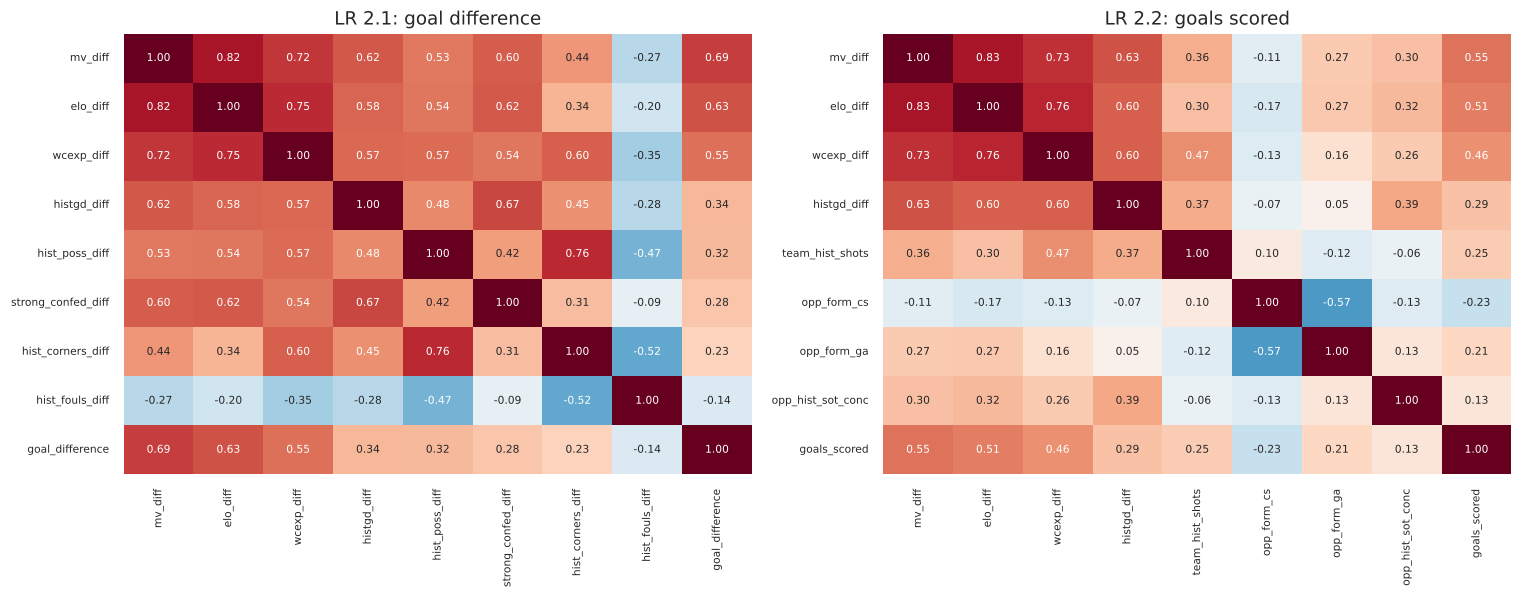

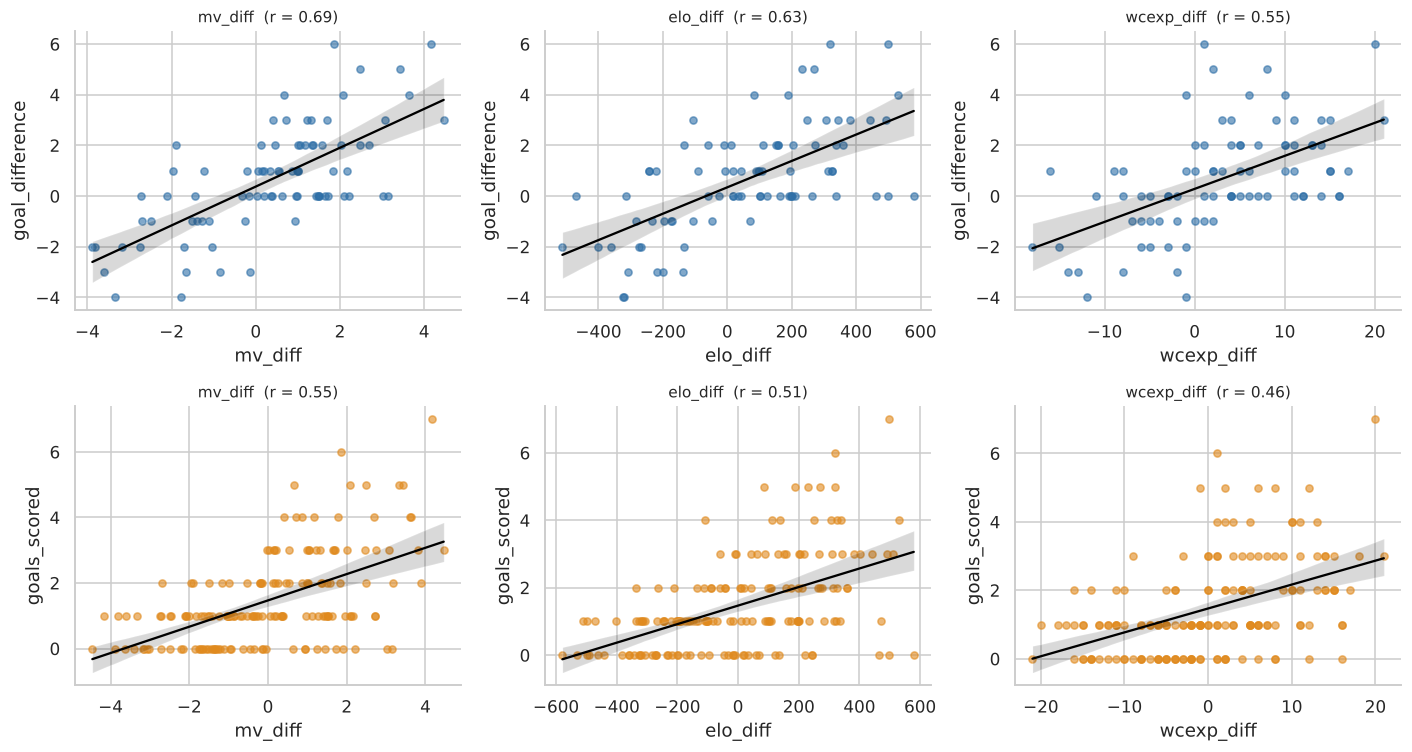

In [14]:
# Figure 3: correlation heatmaps of the chosen variables (training matches only)
fig, axes = plt.subplots(1, 2, figsize=(14, 5.6))
for ax, train, feats, target, title in [(axes[0], tr21, FEATURES_21, T21, "LR 2.1: goal difference"), (axes[1], tr22, FEATURES_22, T22, "LR 2.2: goals scored")]:
    sns.heatmap(train[feats + [target]].corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, cbar=False, ax=ax, annot_kws={"size": 7})
    ax.set_title(title); ax.tick_params(labelsize=7)
plt.tight_layout(); plt.savefig(OUT / "figures/fig3_correlation_heatmaps.png", dpi=200); plt.show()

# Figure 4: scatter plots of the three strongest chosen variables per task
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for row, (train, feats, target, col) in enumerate([(tr21, FEATURES_21, T21, BLUE), (tr22, FEATURES_22, T22, ORANGE)]):
    for ax, f in zip(axes[row], train[feats].corrwith(train[target]).abs().sort_values(ascending=False).index[:3]):
        sns.regplot(data=train, x=f, y=target, ax=ax, color=col, scatter_kws={"alpha": .6, "s": 22}, line_kws={"color": "black", "lw": 1.5})
        ax.set_title(f"{f}  (r = {train[f].corr(train[target]):.2f})", fontsize=10)
plt.tight_layout(); plt.savefig(OUT / "figures/fig4_top_scatter.png", dpi=200); plt.show()

**Result of the selection (training matches only).**

- **Shared four (same variables in both models):** squad value, Elo, World Cup experience and historical World Cup goal difference. They ranked best on average across both tasks. Host nation was fifth, so it was not needed.
- **Unique to LR 2.1:** possession, corners and fouls from 2018/22 and confederation strength.
- **Unique to LR 2.2:** the opponent's clean-sheet rate and goals conceded in 2026 so far, the team's shots per match in 2018/22 and shots on target the opponent conceded in 2018/22.
- Every chosen variable has the sign we expected before looking at the data. All VIFs are below 5.
- **Counting rule check:** exactly 4 shared families and 12 distinct families in total, so we meet the "4 unique + 4 shared" design.

The unique variables are only weakly related to the targets (r between 0.13 and 0.32), much weaker than squad value (r about 0.69 for goal difference). That is honest information for the report: team strength explains most of what we can know before kick-off.

## 7. Linear Regression 2.1 and 2.2: the baseline and five optimisation steps

**What we do.** We fit ordinary multiple linear regression (OLS) on the **83 training matches** and judge it on the **21 later matches** that it has never seen. Every optimisation step below is *fitted on the training set only* (outlier limits, Yeo-Johnson settings, scaler mean and spread) and then *applied* to the test set. The test set is never filtered.

**How we judge.** We use three views, because the test set is small (21 matches):

1. **5-fold cross-validation on the training matches.** Folds are made **by match**, so both team-rows of a match always stay together (otherwise one team's row could train the model while its opponent's row from the same game is tested, which leaks information).
2. **Hold-out test** on the last 21 matches.
3. **Rolling backtest** (later, section 9): re-fit eight times and test on the next 7 matches each time, from match 49 to 104 (56 matches).

Measures: MAE (average miss, in goals), RMSE (punishes big misses) and R². The baseline to beat is "always predict the training average".

In [15]:
# ---------- Helpers used for both tasks ----------
def metrics(y, p):
    return {"MAE": mean_absolute_error(y, p), "RMSE": mean_squared_error(y, p) ** 0.5, "R2": r2_score(y, p)}

class Prep:
    # Pre-processing that is FITTED on training rows only: optional outlier removal, Yeo-Johnson, z-standardisation.
    def __init__(self, outliers=False, yj=False, z=False): self.outliers, self.yj, self.z = outliers, yj, z
    def fit(self, d, feats, target):
        self.feats = feats; self.cont = [f for f in feats if d[f].nunique() > 2]          # 0/1 variables are never transformed
        self.mask = np.ones(len(d), bool)
        if self.outliers:                                                                    # Tukey fences, computed on the training rows
            q1, q3 = d[target].quantile([.25, .75]); iqr = q3 - q1
            self.mask &= d[target].between(q1 - 1.5 * iqr, q3 + 1.5 * iqr).values            # target: 1.5 x IQR
            for f in self.cont:                                                              # variables: wider 3 x IQR fence
                a, b = d[f].quantile([.25, .75]); self.mask &= d[f].between(a - 3 * (b - a), b + 3 * (b - a)).values
        dd = d[self.mask]; X = dd[feats].copy()
        self.pt = self.sc = None
        if self.yj and self.cont:
            self.pt = PowerTransformer(method="yeo-johnson", standardize=False).fit(X[self.cont]); X[self.cont] = self.pt.transform(X[self.cont])
        if self.z: self.sc = StandardScaler().fit(X)
        self.X = self.sc.transform(X) if self.sc else X.values; self.y = dd[target].values
        return self
    def transform(self, d):
        X = d[self.feats].copy()
        if self.pt is not None: X[self.cont] = self.pt.transform(X[self.cont])
        return self.sc.transform(X) if self.sc else X.values

def cv_scores(make_model, train, feats, target, flags, n_splits=5):
    # Grouped 5-fold CV. Pre-processing is re-fitted inside every fold; validation rows are never filtered.
    oof = np.zeros(len(train))
    for a, b in GroupKFold(n_splits).split(train, groups=train.match_id):
        p = Prep(**flags).fit(train.iloc[a], feats, target)
        oof[b] = make_model().fit(p.X, p.y).predict(p.transform(train.iloc[b]))
    return mean_squared_error(train[target], oof) ** 0.5

def stage_eval(name, train, test, feats, target, flags, kept=""):
    p = Prep(**flags).fit(train, feats, target); m = LinearRegression().fit(p.X, p.y)
    t = metrics(test[target], m.predict(p.transform(test)))
    return {"Stage": name, "Kept?": kept, "Training rows used": int(p.mask.sum()), "CV RMSE": cv_scores(LinearRegression, train, feats, target, flags),
            "Test MAE": t["MAE"], "Test RMSE": t["RMSE"], "Test R2": t["R2"], "Train R2": m.score(p.X, p.y)}

TASKS = {"2.1": dict(train=tr21, test=te21, full=m21, feats=FEATURES_21, target=T21),
         "2.2": dict(train=tr22, test=te22, full=m22, feats=FEATURES_22, target=T22)}
stage_rows = {k: [] for k in TASKS}; FLAGS = {k: dict(outliers=False, yj=False, z=False) for k in TASKS}

# ---------- Baseline: plain OLS on the raw variables ----------
for tag, d in TASKS.items():
    row = stage_eval("0. Baseline OLS (raw variables)", d["train"], d["test"], d["feats"], d["target"], FLAGS[tag], "start")
    stage_rows[tag].append(row)
    base = DummyRegressor().fit(d["train"][d["feats"]], d["train"][d["target"]]); b = metrics(d["test"][d["target"]], base.predict(d["test"][d["feats"]]))
    print(f"LR {tag} | mean-only baseline test RMSE = {b['RMSE']:.3f} | OLS test RMSE = {row['Test RMSE']:.3f} | OLS CV RMSE = {row['CV RMSE']:.3f} | train R2 = {row['Train R2']:.3f}")

LR 2.1 | mean-only baseline test RMSE = 1.747 | OLS test RMSE = 1.469 | OLS CV RMSE = 1.559 | train R2 = 0.554
LR 2.2 | mean-only baseline test RMSE = 1.315 | OLS test RMSE = 1.273 | OLS CV RMSE = 1.228 | train R2 = 0.353


**Result.** Plain OLS already beats the mean-only baseline on unseen matches: for LR 2.1 the test RMSE is 1.47 against 1.75; for LR 2.2 it is 1.27 against 1.32. LR 2.1 fits much better than LR 2.2, because the difference between two teams is easier to predict than one team's exact goal count.

### Optimisation 1: remove outliers (training set only)

Rows with an unusually extreme target (more than 1.5 × IQR outside the middle 50%) or an extreme variable (3 × IQR) can pull a straight line towards them. We find the limits **on the training rows**, remove those rows from training, and keep a step **only if it lowers the cross-validated RMSE** of rows that were not filtered.

In [16]:
CUR_CV = {tag: stage_rows[tag][0]["CV RMSE"] for tag in TASKS}   # CV RMSE of the configuration kept so far
def try_step(name, flag_key, tag):
    d = TASKS[tag]; new = {**FLAGS[tag], flag_key: True}
    row = stage_eval(name, d["train"], d["test"], d["feats"], d["target"], new)
    improves = row["CV RMSE"] < CUR_CV[tag] - 1e-9          # compare with the best configuration kept so far
    row["Kept?"] = "yes" if improves else "no (not better in CV)"
    if improves: FLAGS[tag] = new; CUR_CV[tag] = row["CV RMSE"]
    stage_rows[tag].append(row); return row

for tag in TASKS:
    d = TASKS[tag]; p = Prep(outliers=True).fit(d["train"], d["feats"], d["target"])
    flagged = d["train"][~p.mask]
    row = try_step("1. + outlier removal", "outliers", tag)
    print(f"LR {tag}: {int((~p.mask).sum())} of {len(d['train'])} training rows flagged | CV RMSE {stage_rows[tag][0]['CV RMSE']:.3f} -> {row['CV RMSE']:.3f} | kept: {row['Kept?']}")
    if len(flagged): print("   flagged rows (target values):", flagged[d["target"]].tolist()[:12])

LR 2.1: 4 of 83 training rows flagged | CV RMSE 1.559 -> 1.616 | kept: no (not better in CV)
   flagged rows (target values): [6, 6, -4, -4]
LR 2.2: 12 of 166 training rows flagged | CV RMSE 1.228 -> 1.181 | kept: yes
   flagged rows (target values): [1, 7, 6, 3, 2, 0, 3, 1, 3, 3, 2, 1]


**Result.** For LR 2.1 only 4 matches were flagged (two 6-goal margins and two 4-goal margins against the favourite). Removing them made cross-validation *worse* (1.559 to 1.616), so we **kept all rows**: those big wins are real results, not errors. For LR 2.2, 12 high-scoring rows were flagged and removing them improved CV (1.228 to 1.181), so we **kept the step** for LR 2.2.

### Optimisation 2: check for non-linear relationships

A straight line is only right if each variable relates to the target in a roughly straight way. Two checks: (1) a smooth **LOWESS curve** over each scatter plot, and (2) a **squared-term test**: for each continuous variable we add its square to the model and test whether it helps (F-test p-value). We cannot add squared terms to the final model without breaking the 8-variable rule, so this step *tests* for curves; the competing non-linear models in section 9 are the answer if curves exist.

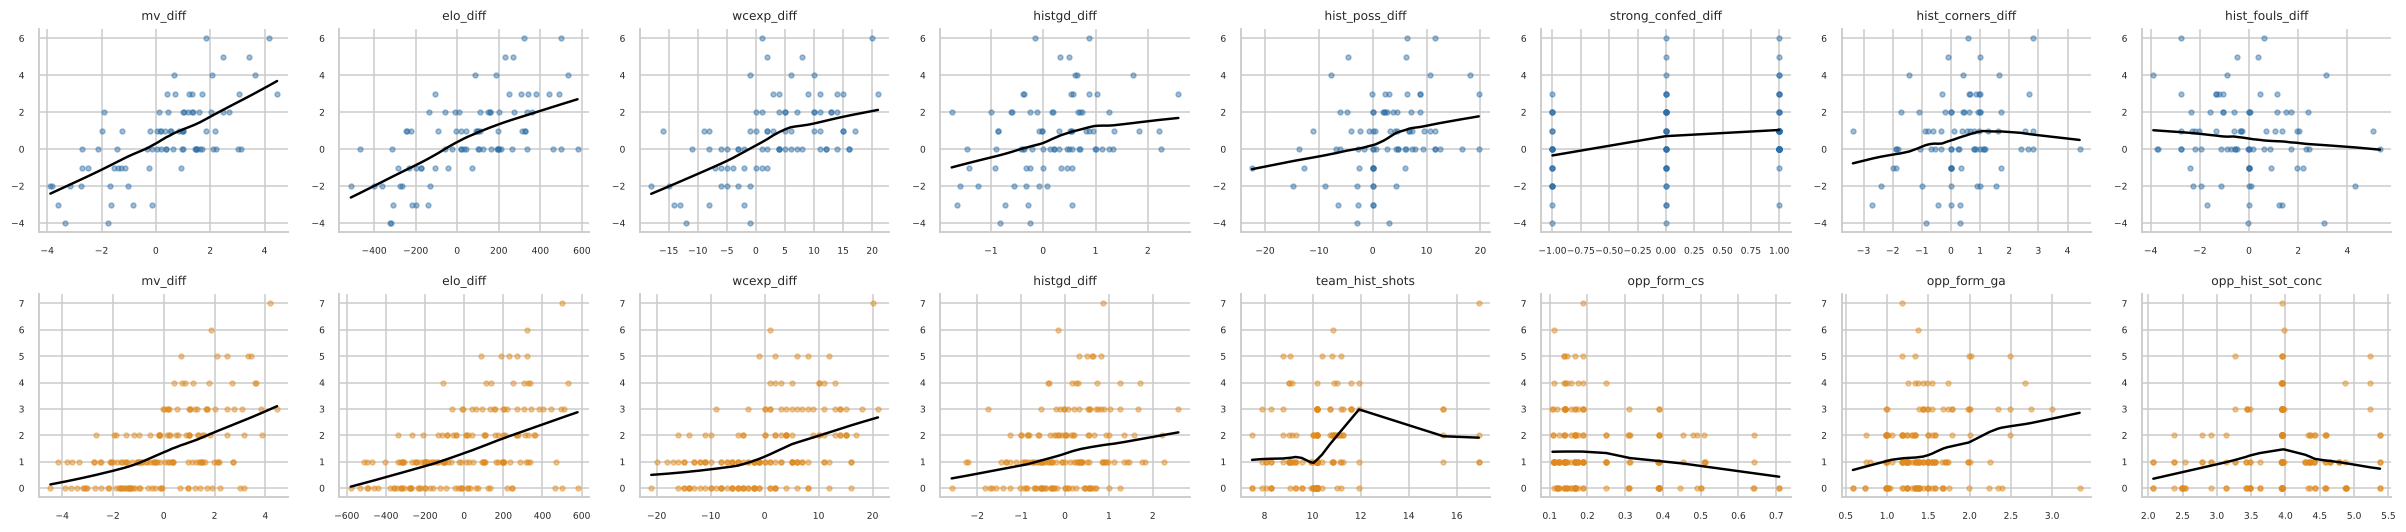

,model,variable,spearman r,pearson r,squared-term p-value
0,2.1,mv_diff,0.654,0.692,0.722
1,2.1,elo_diff,0.618,0.635,0.464
2,2.1,wcexp_diff,0.567,0.549,0.961
3,2.1,histgd_diff,0.341,0.336,0.788
4,2.1,hist_poss_diff,0.332,0.323,0.842
5,2.1,strong_confed_diff,0.266,0.277,0.643
6,2.1,hist_corners_diff,0.233,0.231,0.690
7,2.1,hist_fouls_diff,-0.121,-0.142,0.934
8,2.2,mv_diff,0.522,0.546,0.125
9,2.2,elo_diff,0.511,0.510,0.790


Variables with a significant squared term (p < 0.05): []


In [17]:
rows = []
fig, axes = plt.subplots(2, 8, figsize=(22, 5))
for r_, (tag, col) in enumerate([("2.1", BLUE), ("2.2", ORANGE)]):
    d = TASKS[tag]; tr, feats, target = d["train"], d["feats"], d["target"]
    base_fit = sm.OLS(tr[target], sm.add_constant(tr[feats])).fit()
    for ax, f in zip(axes[r_], feats):
        ax.scatter(tr[f], tr[target], s=10, alpha=.45, color=col)
        if tr[f].nunique() > 2:
            lw = sm.nonparametric.lowess(tr[target], tr[f], frac=.8); ax.plot(lw[:, 0], lw[:, 1], color="black", lw=1.6)
            X2 = sm.add_constant(tr[feats].assign(sq=(tr[f] - tr[f].mean()) ** 2)); f2 = sm.OLS(tr[target], X2).fit()
            p_sq = f2.compare_f_test(base_fit)[1]
        else: p_sq = np.nan
        ax.set_title(f"{f}", fontsize=8); ax.tick_params(labelsize=6)
        rows.append({"model": tag, "variable": f, "spearman r": tr[f].corr(tr[target], method="spearman"), "pearson r": tr[f].corr(tr[target]), "squared-term p-value": p_sq})
plt.tight_layout(); plt.savefig(OUT / "figures/fig5_nonlinearity_check.png", dpi=150); plt.show()
nl = pd.DataFrame(rows); display(nl.round(3))
print("Variables with a significant squared term (p < 0.05):", nl[nl["squared-term p-value"] < .05][["model", "variable"]].values.tolist())

**Result.** No variable has a significant squared term (all p-values above 0.05; the lowest is 0.066), and the LOWESS curves are close to straight. Pearson and Spearman correlations are similar. So the straight-line assumption is reasonable and we add no curves.

### Optimisation 3: check for multicollinearity

Elo, squad value and World Cup experience all measure "how strong is this team", so they are correlated. High correlation makes individual coefficients unstable (large standard errors) even when predictions are fine. We check the **VIF** of each chosen variable (rule of thumb: above 10 is a problem) and the largest correlation between two chosen variables.

In [18]:
for tag, d in TASKS.items():
    X = d["train"][d["feats"]]; v = vif_table(X); c = X.corr().abs().where(~np.eye(len(d["feats"]), dtype=bool))
    i, j = np.unravel_index(np.nanargmax(c.values), c.shape)
    print(f"LR {tag}: highest VIF = {v.max():.1f} ({v.idxmax()}) | strongest correlation between two variables = {c.values[i, j]:.2f} ({d['feats'][i]} & {d['feats'][j]})")
    print("   VIF:", v.round(1).to_dict())

LR 2.1: highest VIF = 4.8 (elo_diff) | strongest correlation between two variables = 0.82 (mv_diff & elo_diff)
   VIF: {'mv_diff': 3.7, 'elo_diff': 4.8, 'wcexp_diff': 3.4, 'histgd_diff': 2.3, 'hist_poss_diff': 3.2, 'strong_confed_diff': 2.2, 'hist_corners_diff': 3.5, 'hist_fouls_diff': 1.5}
LR 2.2: highest VIF = 4.0 (elo_diff) | strongest correlation between two variables = 0.83 (mv_diff & elo_diff)
   VIF: {'mv_diff': 3.8, 'elo_diff': 4.0, 'wcexp_diff': 3.0, 'histgd_diff': 2.1, 'team_hist_shots': 1.5, 'opp_form_cs': 1.5, 'opp_form_ga': 1.7, 'opp_hist_sot_conc': 1.3}


**Result.** The highest VIF is 4.8 (LR 2.1) and 4.0 (LR 2.2), far below 10. Squad value and Elo are correlated at about 0.82, so we keep all variables but read their individual coefficients with care.

### Optimisation 4: Gaussian transformation (Yeo-Johnson)

Linear regression works best when variables are roughly bell-shaped. Several of ours are skewed (World Cup experience, clean-sheet rates). **Yeo-Johnson** is a power transformation that works with negative values, which our difference variables have. The settings (lambda) are learned **on the training rows only**, and 0/1 variables are left alone. We keep it only if cross-validation improves.

In [19]:
from scipy.stats import skew
for tag, d in TASKS.items():
    p = Prep(**{**FLAGS[tag], "yj": True}).fit(d["train"], d["feats"], d["target"])
    cont = p.cont; before = d["train"].loc[p.mask, cont].apply(skew)
    after = pd.DataFrame(p.pt.transform(d["train"].loc[p.mask, cont]), columns=cont).apply(skew)
    prev_cv = CUR_CV[tag]; row = try_step("2. + Yeo-Johnson", "yj", tag)
    print(f"LR {tag}: skewness before -> after:", {c: f'{before[c]:+.2f} -> {after[c]:+.2f}' for c in cont})
    print(f"        CV RMSE of best kept configuration so far {prev_cv:.3f} -> with Yeo-Johnson {row['CV RMSE']:.3f} | kept: {row['Kept?']}")

LR 2.1: skewness before -> after: {'mv_diff': '-0.33 -> +0.06', 'elo_diff': '-0.11 -> +0.01', 'wcexp_diff': '-0.19 -> -0.06', 'histgd_diff': '+0.10 -> +0.04', 'hist_poss_diff': '-0.33 -> +0.04', 'strong_confed_diff': '-0.28 -> -0.12', 'hist_corners_diff': '-0.01 -> +0.10', 'hist_fouls_diff': '+0.49 -> +0.02'}
        CV RMSE of best kept configuration so far 1.559 -> with Yeo-Johnson 1.573 | kept: no (not better in CV)


LR 2.2: skewness before -> after: {'mv_diff': '+0.08 -> +0.01', 'elo_diff': '+0.06 -> +0.02', 'wcexp_diff': '-0.06 -> +0.00', 'histgd_diff': '-0.05 -> +0.00', 'team_hist_shots': '-0.56 -> -0.01', 'opp_form_cs': '+1.55 -> +0.44', 'opp_form_ga': '+0.74 -> -0.01', 'opp_hist_sot_conc': '-0.43 -> -0.01'}
        CV RMSE of best kept configuration so far 1.181 -> with Yeo-Johnson 1.179 | kept: yes


**Result.** Yeo-Johnson brings skewness close to zero for most variables (for example the opponent's goals conceded: +0.74 to -0.01). For LR 2.2 it lowered CV error slightly (1.181 to 1.179), so we **keep it**. For LR 2.1 it made CV error slightly *worse* than the raw variables (1.559 to 1.573), so we **do not use it** for LR 2.1. Honest summary: the transformation matters very little here.

### Optimisation 5: z-standardisation

Each variable is rescaled to mean 0 and standard deviation 1 (mean and spread from the training rows). This does **not** change what an OLS line predicts, but it puts all coefficients on the same scale ("goals per one standard deviation"), so we can compare which variable matters most. It is also needed by the competing models (kNN, SVR, penalised regression).

In [20]:
for tag in TASKS:
    d = TASKS[tag]; FLAGS[tag] = {**FLAGS[tag], "z": True}
    row = stage_eval("3. + z-standardisation", d["train"], d["test"], d["feats"], d["target"], FLAGS[tag], "yes (for comparable coefficients)")
    stage_rows[tag].append(row)
stage_tables = {tag: pd.DataFrame(r).set_index("Stage") for tag, r in stage_rows.items()}
for tag, t in stage_tables.items():
    print(f"\nLR {tag}: every stage (same 20% untouched test matches)"); display(t.round(3))
    print("Final pre-processing for LR", tag, "->", FLAGS[tag])


LR 2.1: every stage (same 20% untouched test matches)


,Kept?,Training rows used,CV RMSE,Test MAE,Test RMSE,Test R2,Train R2
Stage,,,,,,,
0. Baseline OLS (raw variables),start,83,1.559,1.162,1.469,0.079,0.554
1. + outlier removal,no (not better in CV),79,1.616,1.128,1.439,0.117,0.522
2. + Yeo-Johnson,no (not better in CV),83,1.573,1.155,1.454,0.098,0.553
3. + z-standardisation,yes (for comparable coefficients),83,1.559,1.162,1.469,0.079,0.554


Final pre-processing for LR 2.1 -> {'outliers': False, 'yj': False, 'z': True}

LR 2.2: every stage (same 20% untouched test matches)


,Kept?,Training rows used,CV RMSE,Test MAE,Test RMSE,Test R2,Train R2
Stage,,,,,,,
0. Baseline OLS (raw variables),start,166,1.228,0.908,1.273,0.061,0.353
1. + outlier removal,yes,154,1.181,0.907,1.275,0.058,0.334
2. + Yeo-Johnson,yes,154,1.179,0.913,1.273,0.060,0.329
3. + z-standardisation,yes (for comparable coefficients),154,1.179,0.913,1.273,0.060,0.329


Final pre-processing for LR 2.2 -> {'outliers': True, 'yj': True, 'z': True}


**Result.** Z-standardisation changes nothing in the predictions (as expected for OLS) but makes the coefficients comparable. **Final pipeline:** LR 2.1 = z-score only (no outlier removal, no transformation); LR 2.2 = outlier removal + Yeo-Johnson + z-score. The only step with a real CV gain is outlier removal for LR 2.2 (1.228 to 1.181, about 4%); everything else changes the error by less than 0.02 goals, which is within noise on 83 matches.

### Final model, inference and test-set evaluation

We now fit the final OLS model on the fully pre-processed training data with **statsmodels**, to see which coefficients are statistically different from zero. For LR 2.2 each match appears twice, so the rows are not independent; we use **cluster-robust standard errors** (clustered by match) to avoid over-stating certainty.

In [21]:
FINAL = {}
for tag, d in TASKS.items():
    p = Prep(**FLAGS[tag]).fit(d["train"], d["feats"], d["target"])
    Xs = sm.add_constant(pd.DataFrame(p.X, columns=d["feats"])); y = pd.Series(p.y)
    if tag == "2.2": ols = sm.OLS(y, Xs).fit(cov_type="cluster", cov_kwds={"groups": d["train"].match_id.values[p.mask]})
    else:            ols = sm.OLS(y, Xs).fit()
    ci = ols.conf_int()
    coef = pd.DataFrame({"coef (goals per 1 SD)": ols.params, "ci_low": ci[0], "ci_high": ci[1], "p_value": ols.pvalues}).round(3)
    coef["type"] = ["" ] + ["shared" if f in SHARED else "unique" for f in d["feats"]]
    pt = LinearRegression().fit(p.X, p.y).predict(p.transform(d["test"]))
    base_pred = np.full(len(d["test"]), d["train"][d["target"]].mean())
    FINAL[tag] = dict(prep=p, ols=ols, coef=coef, test_pred=pt, test_metrics=metrics(d["test"][d["target"]], pt), base_metrics=metrics(d["test"][d["target"]], base_pred))
    print(f"\n===== LR {tag}: {d['target']} =====")
    display(coef)
    print("R2 = %.3f | adjusted R2 = %.3f | F-test p-value = %.4f" % (ols.rsquared, ols.rsquared_adj, ols.f_pvalue))
    bp = het_breuschpagan(y - ols.fittedvalues, Xs)[1]; print("Breusch-Pagan p-value (constant error spread): %.3f" % bp)
    print("TEST  :", {k: round(v, 3) for k, v in FINAL[tag]["test_metrics"].items()}); print("MEAN-ONLY BASELINE:", {k: round(v, 3) for k, v in FINAL[tag]["base_metrics"].items()})
nd = te21[T21] != 0; acc = (np.sign(FINAL["2.1"]["test_pred"][nd.values]) == np.sign(te21.loc[nd, T21])).mean()
print(f"\nLR 2.1 direction accuracy on the {int(nd.sum())} non-drawn test matches: {acc:.0%}")


===== LR 2.1: goal_difference =====


,coef (goals per 1 SD),ci_low,ci_high,p_value,type
const,0.651,0.328,0.973,0.000,
mv_diff,1.325,0.708,1.942,0.000,shared
elo_diff,0.438,-0.266,1.142,0.219,shared
wcexp_diff,0.381,-0.218,0.980,0.209,shared
histgd_diff,-0.093,-0.579,0.393,0.703,shared
hist_poss_diff,0.017,-0.556,0.591,0.952,unique
strong_confed_diff,-0.562,-1.043,-0.081,0.023,unique
hist_corners_diff,-0.224,-0.826,0.377,0.459,unique
hist_fouls_diff,0.102,-0.288,0.491,0.605,unique


R2 = 0.554 | adjusted R2 = 0.506 | F-test p-value = 0.0000
Breusch-Pagan p-value (constant error spread): 0.035
TEST  : {'MAE': 1.162, 'RMSE': 1.469, 'R2': 0.079}
MEAN-ONLY BASELINE: {'MAE': 1.426, 'RMSE': 1.747, 'R2': -0.302}

===== LR 2.2: goals_scored =====


,coef (goals per 1 SD),ci_low,ci_high,p_value,type
const,1.377,1.186,1.568,0.000,
mv_diff,0.490,0.200,0.779,0.001,shared
elo_diff,0.169,-0.130,0.468,0.267,shared
wcexp_diff,0.136,-0.120,0.392,0.297,shared
histgd_diff,-0.093,-0.281,0.096,0.335,shared
team_hist_shots,0.050,-0.169,0.269,0.656,unique
opp_form_cs,-0.105,-0.322,0.112,0.343,unique
opp_form_ga,0.109,-0.120,0.338,0.352,unique
opp_hist_sot_conc,-0.095,-0.295,0.106,0.356,unique


R2 = 0.329 | adjusted R2 = 0.292 | F-test p-value = 0.0000
Breusch-Pagan p-value (constant error spread): 0.006
TEST  : {'MAE': 0.913, 'RMSE': 1.273, 'R2': 0.06}
MEAN-ONLY BASELINE: {'MAE': 1.045, 'RMSE': 1.315, 'R2': -0.002}

LR 2.1 direction accuracy on the 19 non-drawn test matches: 74%


**How to read the final models.**

- **LR 2.1 (goal difference):** the model explains about 55% of the variance in the training matches (adjusted R² 0.51). Squad value is the clearest driver (+1.3 goals of difference per standard deviation, p < 0.001). Elo and experience point the right way but their intervals include zero, because they overlap with squad value. `strong_confed_diff` has a negative sign even though its simple correlation is positive: once strength is in the model, a UEFA/CONMEBOL team is *weaker* than its rating suggests. This is a classic effect of correlated variables, so we do not read it as "being European hurts". On the 21 unseen matches the model gets RMSE 1.47 against 1.75 for the baseline and picks the winner correctly in 74% of the 19 non-drawn matches.
- **LR 2.2 (goals scored):** a weaker model (R² 0.33, adjusted 0.29). Only squad value is clearly different from zero (+0.49 goals per standard deviation, p = 0.001). Test RMSE is 1.27 against 1.32 for the baseline: a small gain. Cluster-robust standard errors were used because each match appears twice.
- The Breusch-Pagan tests (p = 0.024 and 0.006) suggest the error spread is not perfectly constant, which is common when goals are counts. It makes us treat the p-values as approximate.

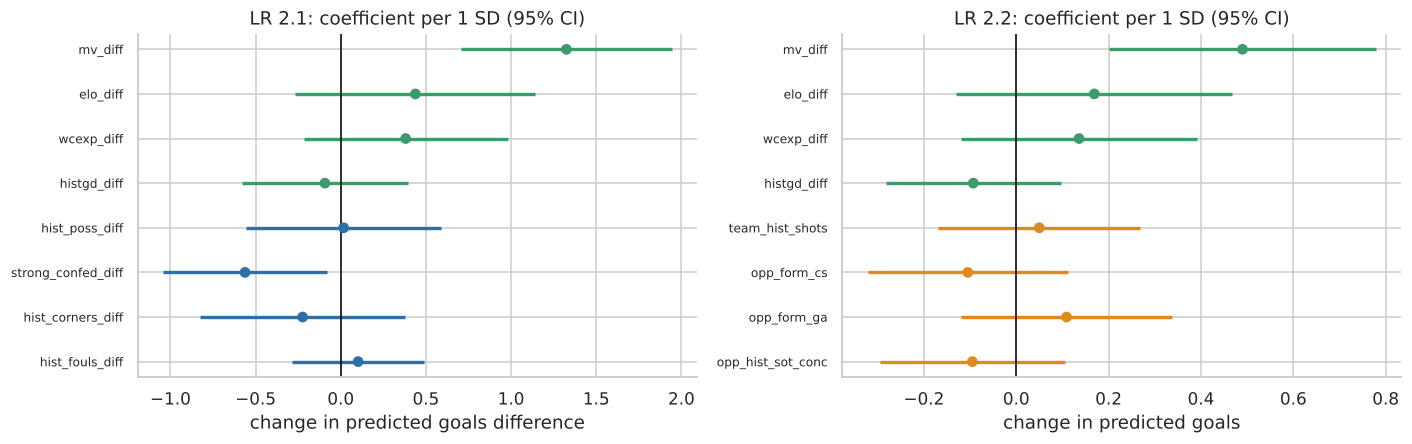

In [22]:
# Figure 6: standardised coefficients with 95% confidence intervals (shared variables in green, unique in blue/orange)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, tag, col in [(axes[0], "2.1", BLUE), (axes[1], "2.2", ORANGE)]:
    c = FINAL[tag]["coef"].iloc[1:]; ypos = np.arange(len(c))[::-1]
    colors = [GREEN if t_ == "shared" else col for t_ in c["type"]]
    ax.hlines(ypos, c.ci_low, c.ci_high, color=colors, lw=2.2); ax.scatter(c["coef (goals per 1 SD)"], ypos, color=colors, zorder=3)
    ax.axvline(0, color="black", lw=1); ax.set_yticks(ypos); ax.set_yticklabels(c.index, fontsize=8)
    ax.set(title=f"LR {tag}: coefficient per 1 SD (95% CI)", xlabel="change in predicted goals" + (" difference" if tag == "2.1" else ""))
plt.tight_layout(); plt.savefig(OUT / "figures/fig6_coefficients.png", dpi=200); plt.show()

## 8. Which variables really matter? (feature analysis)

We take variables out and see what happens to the cross-validated error. This answers two questions: *does the unique half of each model add anything beyond the four shared strength variables?* and *which single variable hurts most when removed?*

LR 2.1


variable set,All 8 variables,4 shared only,4 unique only,Elo difference only,Squad value only,drop mv_diff,drop elo_diff,drop wcexp_diff,drop histgd_diff,drop hist_poss_diff,drop strong_confed_diff,drop hist_corners_diff,drop hist_fouls_diff
CV RMSE,1.559,1.577,2.128,1.691,1.575,1.727,1.571,1.573,1.537,1.525,1.651,1.525,1.532


LR 2.2


variable set,All 8 variables,4 shared only,4 unique only,Elo difference only,Squad value only,drop mv_diff,drop elo_diff,drop wcexp_diff,drop histgd_diff,drop team_hist_shots,drop opp_form_cs,drop opp_form_ga,drop opp_hist_sot_conc
CV RMSE,1.179,1.194,1.388,1.238,1.201,1.224,1.182,1.176,1.175,1.189,1.188,1.181,1.171


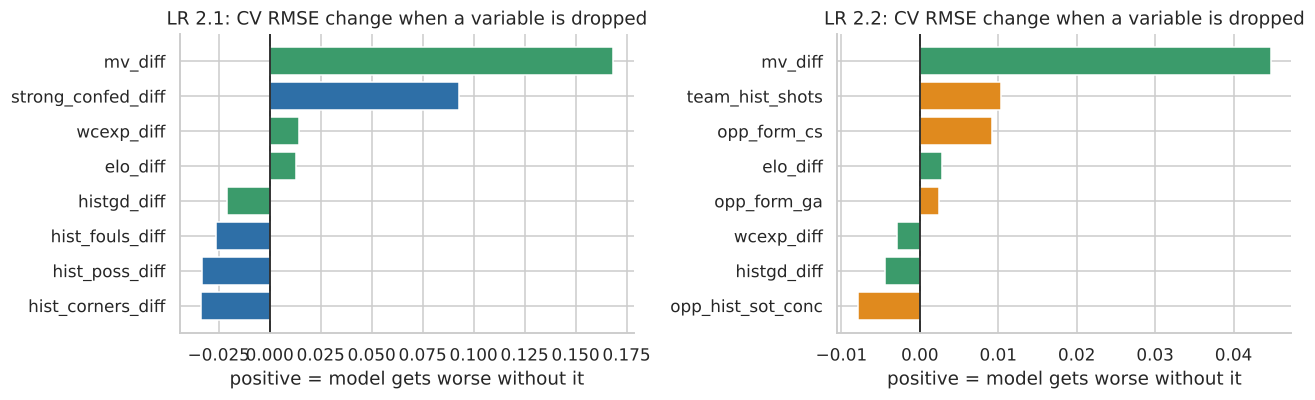

In [23]:
def abl(tag, feats):
    d = TASKS[tag]; return cv_scores(LinearRegression, d["train"], feats, d["target"], FLAGS[tag])
abl_rows = []
for tag, d in TASKS.items():
    uniq = [f for f in d["feats"] if f not in SHARED]; full_cv = abl(tag, d["feats"])
    for name, fs in [("All 8 variables", d["feats"]), ("4 shared only", SHARED), ("4 unique only", uniq), ("Elo difference only", ["elo_diff"]), ("Squad value only", ["mv_diff"])]:
        abl_rows.append({"model": tag, "variable set": name, "CV RMSE": abl(tag, fs)})
    for f in d["feats"]:
        abl_rows.append({"model": tag, "variable set": f"drop {f}", "CV RMSE": abl(tag, [g for g in d["feats"] if g != f])})
ablation = pd.DataFrame(abl_rows)
for tag in TASKS:
    a = ablation[ablation.model == tag].set_index("variable set")["CV RMSE"]; print(f"LR {tag}"); display(a.round(3).to_frame().T)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, tag, col in [(axes[0], "2.1", BLUE), (axes[1], "2.2", ORANGE)]:
    a = ablation[ablation.model == tag].set_index("variable set")["CV RMSE"]; full = a["All 8 variables"]
    delta = pd.Series({f: a[f"drop {f}"] - full for f in TASKS[tag]["feats"]}).sort_values()
    ax.barh(delta.index, delta.values, color=[GREEN if f in SHARED else col for f in delta.index]); ax.axvline(0, color="black", lw=1)
    ax.set(title=f"LR {tag}: CV RMSE change when a variable is dropped", xlabel="positive = model gets worse without it")
plt.tight_layout(); plt.savefig(OUT / "figures/fig7_ablation.png", dpi=200); plt.show()

**What matters.** In both models the **four shared strength variables carry almost all of the information**: LR 2.1 CV RMSE is 1.577 with the shared four only and 1.559 with all eight. Squad value alone (1.575) is as good as all eight. The four unique variables on their own are barely better than guessing the average (2.13 vs a baseline of 2.17 for LR 2.1; 1.39 vs 1.42 for LR 2.2). Dropping confederation strength hurts LR 2.1 most among the unique ones (1.559 to 1.651), which fits the suppressor effect described above. In LR 2.2 dropping any single unique variable changes the error by less than 0.015: they add little.

## 9. Competing regression models, backtest and recommendations

Linear regression is only one family of models. We test eight more from scikit-learn on **exactly the same data** (same 8 variables, same pre-processing, same split): **Ridge, Lasso, Elastic Net** (linear with a penalty), **k-nearest neighbours, support vector regression (SVR)**, **Random Forest, Gradient Boosting** (can learn curves and interactions), and **Poisson regression** for LR 2.2 (goals are counts, so predictions are never negative). A mean-only `DummyRegressor` shows what "no skill" looks like.

Settings are tuned **only inside the training matches** (grouped 5-fold CV, small grids because we have few matches). Each model is then judged by:

- grouped 5-fold **CV RMSE** on the training matches,
- **hold-out test** on the last 21 matches,
- **rolling backtest** on matches 49 to 104 (re-fitting on all earlier matches each time, including the pre-processing). This is our most reliable measure: 56 matches instead of 21, and always looking forward in time.

In [24]:
# ---------- Tune the settings inside the training matches ----------
def tune(model, grid, p, groups):
    gs = GridSearchCV(model, grid, cv=GroupKFold(5), scoring="neg_root_mean_squared_error").fit(p.X, p.y, groups=groups); return gs.best_params_
BEST = {}
for tag, d in TASKS.items():
    p = Prep(**FLAGS[tag]).fit(d["train"], d["feats"], d["target"]); g = d["train"].match_id.values[p.mask]
    BEST[tag] = {"kNN": tune(KNeighborsRegressor(), {"n_neighbors": [5, 10, 20, 30]}, p, g),
                 "SVR": tune(SVR(), {"C": [0.1, 1, 3], "epsilon": [0.1, 0.5], "gamma": ["scale", 0.05]}, p, g),
                 "RF":  tune(RandomForestRegressor(n_estimators=300, random_state=SEED, n_jobs=-1), {"max_depth": [2, 3, 5], "min_samples_leaf": [3, 6, 10]}, p, g),
                 "GB":  tune(HistGradientBoostingRegressor(random_state=SEED, l2_regularization=1.0), {"max_depth": [2, 3], "learning_rate": [0.03, 0.1], "max_iter": [50, 150], "min_samples_leaf": [8, 15]}, p, g)}
    if tag == "2.2": BEST[tag]["Poisson"] = tune(PoissonRegressor(max_iter=1000), {"alpha": [0.1, 1, 10, 30]}, p, g)
    print(tag, BEST[tag])

def model_zoo(tag):
    b = BEST[tag]
    z = {"Mean baseline": lambda: DummyRegressor(), "Linear regression": lambda: LinearRegression(),
         "Ridge": lambda: RidgeCV(alphas=np.logspace(-2, 3, 30)), "Lasso": lambda: LassoCV(cv=5, random_state=SEED, max_iter=20000),
         "Elastic Net": lambda: ElasticNetCV(l1_ratio=[.2, .5, .8], cv=5, random_state=SEED, max_iter=20000),
         "kNN": lambda: KNeighborsRegressor(**b["kNN"]), "SVR": lambda: SVR(**b["SVR"]),
         "Random Forest": lambda: RandomForestRegressor(n_estimators=300, random_state=SEED, n_jobs=-1, **b["RF"]),
         "Gradient Boosting": lambda: HistGradientBoostingRegressor(random_state=SEED, l2_regularization=1.0, **b["GB"])}
    if tag == "2.2": z["Poisson"] = lambda: PoissonRegressor(max_iter=1000, **b["Poisson"])
    return z

def backtest(make_model, full, feats, target, flags, start=48, step=7):
    # Re-fit (pre-processing included) on all matches up to `start`, predict the next `step` matches, move forward. Never sees the future.
    preds = pd.Series(np.nan, index=full.index)
    for s in range(start, int(full.match_id.max()), step):
        trn, tst = full[full.match_id <= s], full[(full.match_id > s) & (full.match_id <= s + step)]
        p = Prep(**flags).fit(trn, feats, target); preds.loc[tst.index] = make_model().fit(p.X, p.y).predict(p.transform(tst))
    ok = preds.notna(); return metrics(full.loc[ok, target], preds[ok]), preds[ok]

2.1 {'kNN': {'n_neighbors': 10}, 'SVR': {'C': 1, 'epsilon': 0.1, 'gamma': 0.05}, 'RF': {'max_depth': 2, 'min_samples_leaf': 10}, 'GB': {'learning_rate': 0.03, 'max_depth': 2, 'max_iter': 50, 'min_samples_leaf': 15}}


2.2 {'kNN': {'n_neighbors': 10}, 'SVR': {'C': 1, 'epsilon': 0.5, 'gamma': 0.05}, 'RF': {'max_depth': 3, 'min_samples_leaf': 3}, 'GB': {'learning_rate': 0.03, 'max_depth': 2, 'max_iter': 50, 'min_samples_leaf': 8}, 'Poisson': {'alpha': 1}}


In [25]:
COMPARE, BT_PRED, TEST_PRED = {}, {}, {}
for tag, d in TASKS.items():
    p = Prep(**FLAGS[tag]).fit(d["train"], d["feats"], d["target"]); rows = []
    for name, mk in model_zoo(tag).items():
        oof = np.zeros(len(d["train"])); 
        for a, b in GroupKFold(5).split(d["train"], groups=d["train"].match_id):
            pp = Prep(**FLAGS[tag]).fit(d["train"].iloc[a], d["feats"], d["target"]); oof[b] = mk().fit(pp.X, pp.y).predict(pp.transform(d["train"].iloc[b]))
        cv = mean_squared_error(d["train"][d["target"]], oof) ** 0.5
        pt = mk().fit(p.X, p.y).predict(p.transform(d["test"])); t = metrics(d["test"][d["target"]], pt)
        bt, bp = backtest(mk, d["full"], d["feats"], d["target"], FLAGS[tag]); BT_PRED[(tag, name)], TEST_PRED[(tag, name)] = bp, pt
        rows.append({"Model": name, "CV RMSE": cv, "Test MAE": t["MAE"], "Test RMSE": t["RMSE"], "Test R2": t["R2"],
                     "Backtest MAE": bt["MAE"], "Backtest RMSE": bt["RMSE"], "Backtest R2": bt["R2"]})
    COMPARE[tag] = pd.DataFrame(rows).set_index("Model")
    print(f"\nLR {tag}: all models, same variables and same splits (sorted by backtest RMSE; lower is better)"); display(COMPARE[tag].sort_values("Backtest RMSE").round(3))
    COMPARE[tag].to_csv(OUT / f"model_comparison_{tag.replace('.', '')}.csv")


LR 2.1: all models, same variables and same splits (sorted by backtest RMSE; lower is better)


,CV RMSE,Test MAE,Test RMSE,Test R2,Backtest MAE,Backtest RMSE,Backtest R2
Model,,,,,,,
SVR,1.672,0.951,1.256,0.328,1.024,1.292,0.489
Ridge,1.553,1.130,1.433,0.125,1.061,1.323,0.465
Linear regression,1.559,1.162,1.469,0.079,1.086,1.335,0.454
Random Forest,1.704,1.060,1.347,0.227,1.072,1.349,0.443
Elastic Net,1.552,1.109,1.410,0.153,1.058,1.350,0.443
Lasso,1.557,1.121,1.417,0.143,1.063,1.356,0.437
kNN,1.699,1.067,1.432,0.125,1.079,1.358,0.436
Gradient Boosting,1.752,1.165,1.488,0.056,1.131,1.439,0.366
Mean baseline,2.171,1.426,1.747,-0.302,1.526,1.956,-0.171



LR 2.2: all models, same variables and same splits (sorted by backtest RMSE; lower is better)


,CV RMSE,Test MAE,Test RMSE,Test R2,Backtest MAE,Backtest RMSE,Backtest R2
Model,,,,,,,
Random Forest,1.187,0.960,1.224,0.131,0.888,1.129,0.232
Gradient Boosting,1.217,0.950,1.234,0.118,0.867,1.139,0.219
SVR,1.253,0.867,1.239,0.111,0.870,1.141,0.215
Lasso,1.214,0.918,1.252,0.092,0.900,1.144,0.212
Elastic Net,1.199,0.917,1.261,0.078,0.896,1.150,0.203
kNN,1.200,0.969,1.242,0.107,0.914,1.163,0.186
Ridge,1.192,0.917,1.273,0.061,0.920,1.183,0.158
Poisson,1.186,0.926,1.290,0.036,0.917,1.184,0.156
Linear regression,1.179,0.913,1.273,0.060,0.967,1.248,0.063


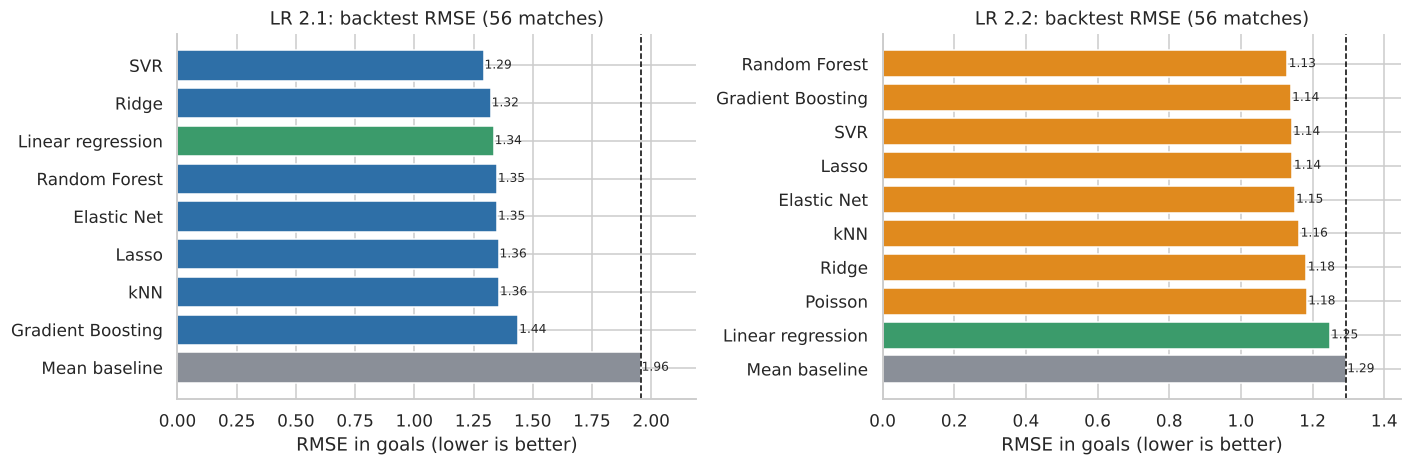

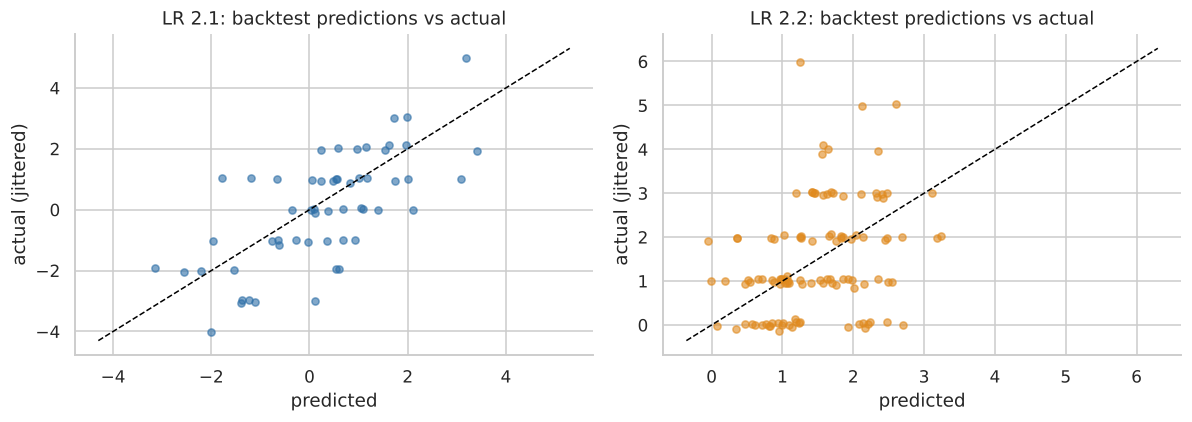

In [26]:
# Figure 8: model comparison. The dashed line is the mean-only baseline: a model must be left of it to have any skill.
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
for ax, tag, col in [(axes[0], "2.1", BLUE), (axes[1], "2.2", ORANGE)]:
    c = COMPARE[tag]["Backtest RMSE"].sort_values()
    ax.barh(c.index, c.values, color=[GREY if n == "Mean baseline" else (GREEN if n == "Linear regression" else col) for n in c.index]); ax.invert_yaxis()
    ax.axvline(COMPARE[tag].loc["Mean baseline", "Backtest RMSE"], color="black", ls="--", lw=1)
    for y_, v_ in enumerate(c.values): ax.text(v_ + .004, y_, f"{v_:.2f}", va="center", fontsize=8)
    ax.set(title=f"LR {tag}: backtest RMSE (56 matches)", xlabel="RMSE in goals (lower is better)", xlim=(0, c.max() * 1.12))
plt.tight_layout(); plt.savefig(OUT / "figures/fig8_model_comparison.png", dpi=200); plt.show()

# Figure 9: predictions vs reality for linear regression on the backtest matches
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, tag, col in [(axes[0], "2.1", BLUE), (axes[1], "2.2", ORANGE)]:
    d = TASKS[tag]; bp = BT_PRED[(tag, "Linear regression")]; y_ = d["full"].loc[bp.index, d["target"]]
    ax.scatter(bp, y_ + np.random.default_rng(1).normal(0, .06, len(y_)), color=col, alpha=.6, s=22)
    lim = [min(bp.min(), y_.min()) - .3, max(bp.max(), y_.max()) + .3]; ax.plot(lim, lim, color="black", lw=1, ls="--")
    ax.set(title=f"LR {tag}: backtest predictions vs actual", xlabel="predicted", ylabel="actual (jittered)")
plt.tight_layout(); plt.savefig(OUT / "figures/fig9_pred_vs_actual.png", dpi=200); plt.show()

In [27]:
# How sure are we? Bootstrap over MATCHES (not rows), so both team-rows of a match stay together. Positive = the first model is better (lower RMSE).
def boot_gain(tag, name_a, name_b, n=2000):
    d = TASKS[tag]; pa, pb = BT_PRED[(tag, name_a)], BT_PRED[(tag, name_b)]
    e = d["full"].loc[pa.index, ["match_id", d["target"]]].copy(); e["a"] = (e[d["target"]] - pa) ** 2; e["b"] = (e[d["target"]] - pb) ** 2
    pm = e.groupby("match_id")[["a", "b"]].mean().values; rng = np.random.default_rng(SEED)
    idx = rng.integers(0, len(pm), (n, len(pm))); gain = np.sqrt(pm[idx, 1].mean(1)) - np.sqrt(pm[idx, 0].mean(1))
    return np.percentile(gain, [2.5, 50, 97.5])

boot_rows = []
for tag in TASKS:
    best_other = COMPARE[tag].drop(["Mean baseline", "Linear regression"])["Backtest RMSE"].idxmin()
    for a_, b_ in [("Linear regression", "Mean baseline"), (best_other, "Linear regression"), (best_other, "Mean baseline")]:
        lo, mid, hi = boot_gain(tag, a_, b_); boot_rows.append({"LR": tag, "comparison": f"{a_} better than {b_}", "RMSE gain (goals)": mid, "95% CI low": lo, "95% CI high": hi,
                                                                 "CI excludes 0?": "yes" if lo > 0 or hi < 0 else "no"})
boot = pd.DataFrame(boot_rows); display(boot.round(3))

,LR,comparison,RMSE gain (goals),95% CI low,95% CI high,CI excludes 0?
0,2.1,Linear regression better than Mean baseline,0.626,0.271,0.955,yes
1,2.1,SVR better than Linear regression,0.043,-0.133,0.208,no
2,2.1,SVR better than Mean baseline,0.666,0.441,0.888,yes
3,2.2,Linear regression better than Mean baseline,0.049,-0.064,0.170,no
4,2.2,Random Forest better than Linear regression,0.116,0.021,0.211,yes
5,2.2,Random Forest better than Mean baseline,0.164,0.061,0.271,yes


**Result of the model comparison.**

- **LR 2.1:** all models beat the mean baseline by a wide margin (backtest RMSE about 1.3 to 1.4 vs 1.96). SVR is nominally best (1.29), but plain linear regression (1.34) and Ridge (1.32) are almost the same: the bootstrap gain of SVR over linear regression is +0.04 goals with a 95% interval of -0.13 to +0.21, so **there is no evidence that a more complex model helps**.
- **LR 2.2:** linear regression (1.25) is barely better than the baseline (1.29); its bootstrap gain is +0.05 with an interval from -0.06 to +0.17. Random Forest (1.13), Gradient Boosting, SVR and penalised linear models do better. The Random Forest gain over linear regression is +0.12 goals (95% interval +0.02 to +0.21), which excludes zero.
- **Recommendation.** For goal difference (LR 2.1) use the simple, explainable **Ridge or plain linear regression**. For goals scored (LR 2.2) a penalised linear model (Lasso/Elastic Net) is the best simple choice, and Random Forest gives the lowest error, but all differences between the top models are small compared with how noisy football is. No model comes close to predicting single matches exactly: goals are largely random.

## 10. Summary tables used in the report

In [28]:
summary = []
for tag, d in TASKS.items():
    c, ols = COMPARE[tag], FINAL[tag]["ols"]; best = c.drop("Mean baseline")["Backtest RMSE"].idxmin()
    summary.append({"LR": tag, "target": d["target"], "rows": len(d["full"]), "variables": len(d["feats"]), "shared": 4, "unique": 4,
                    "OLS train R2": ols.rsquared, "OLS adj R2": ols.rsquared_adj, "OLS CV RMSE": c.loc["Linear regression", "CV RMSE"],
                    "OLS test RMSE": c.loc["Linear regression", "Test RMSE"], "baseline test RMSE": c.loc["Mean baseline", "Test RMSE"],
                    "OLS backtest RMSE": c.loc["Linear regression", "Backtest RMSE"], "baseline backtest RMSE": c.loc["Mean baseline", "Backtest RMSE"],
                    "best model (backtest)": best})
summary = pd.DataFrame(summary); display(summary.round(3))

# Final datasets: exactly the required shape (ID columns are not explanatory variables)
ds21 = m21[["match_id", "date", "home_team", "away_team", T21] + FEATURES_21]; ds22 = m22[["match_id", "date", "team", "opp", T22] + FEATURES_22]
assert ds21.shape == (104, 5 + 8) and ds22.shape == (208, 5 + 8)
ds21.to_csv(OUT / "lr21_final_dataset.csv", index=False); ds22.to_csv(OUT / "lr22_final_dataset.csv", index=False)
m21.to_csv(OUT / "lr21_all_candidates.csv", index=False); m22.to_csv(OUT / "lr22_all_candidates.csv", index=False)
summary.to_csv(OUT / "summary_table.csv", index=False); boot.to_csv(OUT / "bootstrap_table.csv", index=False)
pd.concat(stage_tables, names=["LR"]).to_csv(OUT / "optimisation_stages.csv")
final_vars = pd.DataFrame({"LR 2.1": FEATURES_21, "LR 2.2": FEATURES_22}); display(final_vars)
print("Shared (4):", SHARED); print("Unique to 2.1:", UNIQUE21); print("Unique to 2.2:", UNIQUE22)
print("Saved final datasets, tables and figures in:", OUT.resolve())

,LR,target,rows,variables,shared,unique,OLS train R2,OLS adj R2,OLS CV RMSE,OLS test RMSE,baseline test RMSE,OLS backtest RMSE,baseline backtest RMSE,best model (backtest)
0,2.1,goal_difference,104,8,4,4,0.554,0.506,1.559,1.469,1.747,1.335,1.956,SVR
1,2.2,goals_scored,208,8,4,4,0.329,0.292,1.179,1.273,1.322,1.248,1.293,Random Forest


,LR 2.1,LR 2.2
0,mv_diff,mv_diff
1,elo_diff,elo_diff
2,wcexp_diff,wcexp_diff
3,histgd_diff,histgd_diff
4,hist_poss_diff,team_hist_shots
5,strong_confed_diff,opp_form_cs
6,hist_corners_diff,opp_form_ga
7,hist_fouls_diff,opp_hist_sot_conc


Shared (4): ['mv_diff', 'elo_diff', 'wcexp_diff', 'histgd_diff']
Unique to 2.1: ['hist_poss_diff', 'strong_confed_diff', 'hist_corners_diff', 'hist_fouls_diff']
Unique to 2.2: ['team_hist_shots', 'opp_form_cs', 'opp_form_ga', 'opp_hist_sot_conc']
Saved final datasets, tables and figures in: /home/claude/FINAL_SUBMISSION_CODE_DOCS/output


**Conclusion.** Both tasks use 8 variables known before kick-off, with exactly 4 shared and 4 unique each (12 distinct in total). Using external sources (Elo, squad value, World Cup history and 2018/2022 playing style) gave us a model that predicts goal difference clearly better than the average (RMSE 1.34 vs 1.96 in the backtest) and goals scored slightly better. The main finding is that **pre-match team strength, especially squad market value, explains most of what is predictable**, while style variables add little. The main limits are small sample size (104 matches), the fact that no 2026 odds or match statistics were available to us, and the randomness of football.